# 02. Conditional Generation과 Guidance: 원하는 숫자 생성하기

01에서는 noise에서 임의의 숫자 이미지를 생성했다. 이번에는 숫자 label $y$를 지정해 원하는 숫자를 생성하고, condition을 더 강하게 반영하면 결과가 어떻게 달라지는지 확인한다. **01의 MNIST·MLP·linear Gaussian path를 유지하고 conditioning과 guidance를 추가**한다.

교재 *An Introduction to Flow Matching and Diffusion Models*의 Ch.5를 따라 **vanilla guidance → classifier guidance → classifier-free guidance(CFG)** 순서로 수식을 유도하고 코드로 구현한다. 교재의 $u_t$를 여기서는 $v_t$로 쓴다.

| 방법 | 사용하는 모델 | 비교 목적 |
| --- | --- | --- |
| Unconditional baseline | 01의 학습된 Flow 또는 Noise 모델 | label 없이 생성한 결과 |
| Vanilla conditional | 02에서 label dropout으로 학습한 생성 모델의 conditional branch | label을 입력하는 효과 |
| Classifier guidance (CG) | 01의 unconditional 모델 + 새 time-dependent classifier | classifier gradient로 유도하는 효과 |
| Classifier-free guidance (CFG) | 02의 같은 생성 모델의 conditional·null branch | 별도 classifier 없이 condition을 강조하는 효과 |

이 notebook에서는 01에서 학습한 Flow Matching과 Diffusion에 label 정보를 추가해, 원하는 숫자를 생성하는 방법을 살펴본다. 먼저 label을 입력으로 받는 conditional generation을 구현하고, classifier guidance와 classifier-free guidance가 생성 방향을 어떻게 조정하는지 수식과 코드로 연결한다.

같은 initial noise에서 생성한 이미지와 trajectory를 비교하면서, guidance의 강도가 숫자의 형태와 다양성에 어떤 영향을 주는지 관찰한다. 두 guidance 방법은 필요한 모델과 학습 과정이 다르므로, 결과를 해석할 때 이러한 차이도 함께 살펴본다.

MNIST split, normalization, 생성 MLP의 width/depth, optimizer, LR schedule, epoch 수는 01과 맞춘다. 새로운 생성 모델은 처음부터 학습하고, 01 checkpoint는 baseline과 CG에만 사용한다. 학습된 결과는 이 notebook을 실행한 뒤 해석한다.

In [ ]:
# Google Colab GPU runtime에서 위에서부터 실행한다. 01의 학습 완료 checkpoint가 필요하다.
import math, time, copy, random, json, os, platform
from pathlib import Path
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import torchvision
import matplotlib.pyplot as plt

SEED, BATCH = 42, 256
WIDTH, DEPTH = 1024, 3
LR, MIN_LR = 2e-4, 1e-6
MAX_EPOCHS, SCHEDULE_EPOCHS = 300, 300  # resume 시 SCHEDULE_EPOCHS는 유지한다.
LABEL_DROP = 0.1
NULL_LABEL = 10  # 실제 label 0~9와 구분하는 null token
CLASSIFIER_WIDTH, CLASSIFIER_DEPTH = 512, 2
CLASSIFIER_EPOCHS, CLASSIFIER_SCHEDULE = 50, 50
CLASSIFIER_LR = 2e-4
RESUME_CONDITIONAL = True
RESUME_CLASSIFIER = True
SAVE_TO_DRIVE = True

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive')
else:
    ROOT = Path('/content')  # 임시 runtime 저장소. 종료 시 checkpoint가 사라질 수 있다.

# 01의 실제 저장 위치에 맞춘다. snapshot epoch_0300.pt와 전체 상태 last.pt 모두 지원한다.
BASELINE_CKPT = ROOT / 'MNIST_Controlled_Comparison/run_v1/last.pt'
# 새 실험은 run 이름을 바꾼다. resume은 같은 경로와 설정을 사용한다.
RUN_DIR = ROOT / 'MNIST_Guidance/run_v1'
COND_CKPT = RUN_DIR / 'conditional/last.pt'
CLASSIFIER_CKPT = RUN_DIR / 'classifier/last.pt'
assert 1 <= MAX_EPOCHS <= SCHEDULE_EPOCHS
assert 1 <= CLASSIFIER_EPOCHS <= CLASSIFIER_SCHEDULE
assert 0 < LABEL_DROP < 1
if not BASELINE_CKPT.exists():
    raise FileNotFoundError(f'01 checkpoint가 필요합니다. BASELINE_CKPT를 확인하세요: {BASELINE_CKPT}')
for path, resume in [(COND_CKPT, RESUME_CONDITIONAL), (CLASSIFIER_CKPT, RESUME_CLASSIFIER)]:
    if path.exists() and not resume:
        raise FileExistsError(f'{path}: resume을 켜거나 새 RUN_DIR을 지정하세요.')
    if resume and not path.exists():
        raise FileNotFoundError(f'resume할 checkpoint가 없습니다: {path}')
RUN_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ENV = dict(python=platform.python_version(), torch=torch.__version__,
           torchvision=torchvision.__version__, numpy=np.__version__,
           device=str(device), gpu=torch.cuda.get_device_name() if device.type=='cuda' else None)
print(ENV)

Mounted at /content/drive
{'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'numpy': '2.4.6', 'device': 'cuda', 'gpu': 'Tesla T4'}


## 1. 같은 데이터에 label 추가하기

01과 같은 seed로 MNIST를 55,000 / 5,000 / 10,000으로 나누고 pixel을 [-1,1]로 변환한다. 이번에는 loader가 반환하는 이미지 $z$와 label $y$를 둘 다 사용한다. Null label은 이미지의 class가 아니라, 모델에 class 정보를 주지 않는다는 표시다.

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 474kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.54MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.42MB/s]


train / validation / test: 55000 5000 10000
Preview labels: [6, 7, 6, 9, 4, 2, 1, 3, 8, 9, 7, 0, 3, 1, 2, 4]


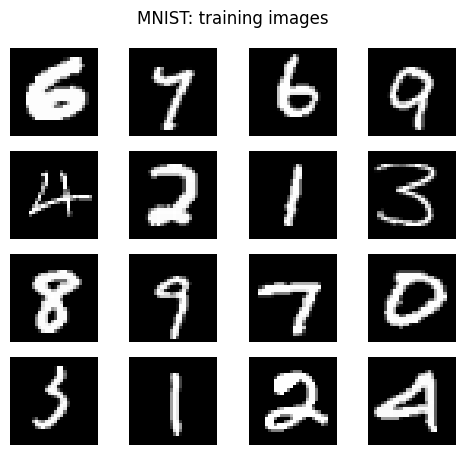

In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.5,), (.5,))])
full_train = datasets.MNIST('/content/data', train=True, download=True, transform=transform)
train, val = random_split(full_train, [55000, 5000], generator=torch.Generator().manual_seed(SEED))
test = datasets.MNIST('/content/data', train=False, download=True, transform=transform)
# 두 학습의 shuffle/RNG 상태를 독립적으로 저장한다.
cond_order = torch.Generator().manual_seed(SEED)
clf_order = torch.Generator().manual_seed(SEED+100)
cond_loader = DataLoader(train, batch_size=BATCH, shuffle=True, generator=cond_order, num_workers=0)
clf_loader = DataLoader(train, batch_size=BATCH, shuffle=True, generator=clf_order, num_workers=0)
val_loader = DataLoader(val, batch_size=BATCH, shuffle=False, num_workers=0)
test_loader = DataLoader(test, batch_size=BATCH, shuffle=False, num_workers=0)
print('train / validation / test:', len(train), len(val), len(test))

def show_grid(x, title, cols=4):
    x = x.detach().cpu().reshape(-1,28,28)
    rows = math.ceil(len(x)/cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols*1.25, rows*1.15), squeeze=False)
    for ax, im in zip(axes.flat, x):
        ax.imshow(im.clamp(-1,1), cmap='gray', vmin=-1, vmax=1)  # 표시할 때만 clipping
    for ax in axes.flat: ax.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

preview = torch.stack([train[i][0] for i in range(16)])
print('Preview labels:', [train[i][1] for i in range(16)])
show_grid(preview, 'MNIST: training images')

## 2. Vanilla guidance: 입력에 label을 주면 target도 달라질까?

### 2.1 일반식: image conditioning과 label conditioning

01의 $p_t(x\mid z)$는 **원본 이미지 $z$를 고정한 path**다. 이번에 원하는 것은 **숫자 label $y$를 고정한 path**다.

$$p_t(x\mid y)=\int p_t(x\mid z)p_{\mathrm{data}}(z\mid y)\,dz.$$

예를 들어 $y=7$이면 다양한 숫자 7 이미지 주위의 conditional distribution을 섞는다. $z$가 정해지면 noise를 섞는 방법은 label에 의존하지 않도록 설계한다. 따라서 $p_t(x\mid z,y)=p_t(x\mid z)$다.

01과 같은 marginalization으로

$$v_t(x\mid y)=\mathbb E[v_t(x_t\mid z)\mid x_t=x,y].$$

네트워크가 배워야 하는 것은 왼쪽의 label-conditioned velocity지만, 학습 target은 오른쪽 평균 안의 계산 가능한 $v_t(x_t\mid z)$다. $Y=v_t(x_t\mid z)$, $m=\mathbb E[Y\mid x_t,t,y]$라 두면

$$\mathbb E[\lVert v_\theta-Y\rVert^2]
=\mathbb E[\lVert v_\theta-m\rVert^2]+\mathbb E[\lVert Y-m\rVert^2].$$

마지막 항은 $\theta$와 무관하므로 두 loss의 $\theta$에 대한 gradient는 같다. 따라서 직접 계산하기 어려운 $v_t(x_t\mid y)$ 대신, 학습 sample $z$로 계산할 수 있는 $v_t(x_t\mid z)$를 target으로 사용해도 된다. **모델의 입력은 두 경우 모두 $(x_t,t,y)$로 같고, loss를 계산할 때 사용하는 target만 달라진다.**

$$
\boxed{
\nabla_\theta
\mathbb{E}_{t,z,y,x_t}
\left[
\left\|v_\theta(x_t,t,y)-v_t(x_t\mid z)\right\|^2
\right]
=
\nabla_\theta
\mathbb{E}_{t,y,x_t}
\left[
\left\|v_\theta(x_t,t,y)-v_t(x_t\mid y)\right\|^2
\right]
}
$$



교재 식 (57)은 $y$를 고정한 경우이고, 식 (58)은 실제 dataset에서 $(z,y)$ 쌍을 뽑아 모든 label에 대해 학습하는 경우다.

$$\mathcal L_{\mathrm{guided}}=
\mathbb E_{(z,y),t,x_t}\left[\frac1{784}\lVert v_\theta(x_t,t,y)-v_t(x_t\mid z)\rVert^2\right].$$

### 2.2 Gaussian path와 현재 계수 대입

$$x_t=\alpha_tz+\beta_t\epsilon,\quad
v_t(x_t\mid z)=\dot\alpha_tz+\dot\beta_t\epsilon.$$

01과 동일하게 $\alpha_t=t$, $\beta_t=1-t$를 넣으면

$$x_t=tz+(1-t)\epsilon,\qquad \boxed{v_{\mathrm{target}}=z-\epsilon}.$$

Noise prediction에서도 target은 여전히 $\epsilon$이다. Label에 따라 **입력에서 유추할 수 있는 정보가 달라지지만**, sample을 만들 때 사용한 noise와 conditional velocity의 계산식은 바뀌지 않는다.

```python
xt = t*z + (1-t)*eps
flow_loss = (flow(xt, t, y) - (z-eps)).square().mean()
noise_loss = (noise(xt, t, y) - eps).square().mean()
```

*교재: §5.1, 식 (57)–(58), pp.34–35.*

## 3. Classifier guidance: classifier의 gradient로 방향 바꾸기

### 3.1 Bayes' rule에서 시작하기

$$p_t(x\mid y)=\frac{p_t(x)p_t(y\mid x)}{p_t(y)}.$$

Log를 취한 뒤 $x$에 대해 gradient를 계산하면 $p_t(y)$는 $x$와 무관하므로 사라진다.

$$s_t(x\mid y)=s_t(x)+\nabla_x\log p_t(y\mid x).$$

01의 Gaussian velocity–score 관계는 $v_t(x)=a_ts_t(x)+b_tx$이고,

$$a_t=\frac{\dot\alpha_t\beta_t^2}{\alpha_t}-\dot\beta_t\beta_t,
\qquad b_t=\frac{\dot\alpha_t}{\alpha_t}.$$

Conditional score를 넣어 전개하면

$$\begin{aligned}
v_t(x\mid y)&=a_t[s_t(x)+\nabla_x\log p_t(y\mid x)]+b_tx\\
&=v_t(x)+a_t\nabla_x\log p_t(y\mid x).
\end{aligned}$$

Condition의 영향을 $w$배 강조하면 교재 식 (62)가 된다.

$$\boxed{\widetilde v_{\mathrm{CG}}(x,t,y)=v_\theta(x,t)+w a_t\nabla_x\log p_\phi(y\mid x,t).}$$

현재 $\alpha_t=t$, $\beta_t=1-t$에서는

$$a_t=\frac{(1-t)^2}{t}+(1-t)=\boxed{\frac{1-t}{t}}.$$

즉, classifier gradient를 그냥 더하지 않고 **$(1-t)/t$를 곱해서** velocity에 더한다. $w=0$이면 01 baseline, $w=1$이면 정확한 모델이라는 이상적인 조건에서 vanilla conditional velocity, $w>1$이면 condition을 더 강조한다. 작은 $t$에서는 이 계수가 커지므로 classifier의 부정확한 gradient도 크게 영향을 줄 수 있다.

### 3.2 우리가 학습할 classifier

Classifier는 clean 이미지뿐 아니라 각 시간의 noisy 이미지에서 $p_\phi(y\mid x_t,t)$를 예측해야 한다.

$$\boxed{\mathcal L_{\mathrm{clf}}=-\mathbb E_{(z,y),t,\epsilon}\log p_\phi(y\mid tz+(1-t)\epsilon,t).}$$

```python
logits = classifier(xt, t)       # [batch, 10]
loss = F.cross_entropy(logits, y)
```

생성할 때 필요한 것은 argmax label이 아니라 **원하는 label의 log-probability를 입력 $x$로 미분한 값**이다. 학습에서는 classifier parameters를 업데이트하고, 생성에서는 parameters를 고정한 채 입력 gradient만 계산한다.

$t=0$에서는 입력이 순수 noise여서 label 정보가 없다. 따라서 모든 시간에서 높은 accuracy를 기대하면 안 된다. 뒤에서 real validation 데이터에 대한 accuracy를 시간별로 확인한다.

*교재: §5.2, 식 (59)–(62), pp.36–37. Cross-entropy 학습 코드는 해당 설명을 MNIST에 적용한 것이다.*

## 4. CFG: classifier를 따로 학습하지 않고 같은 방향 만들기

앞 식에서

$$a_t\nabla_x\log p_t(y\mid x)=v_t(x\mid y)-v_t(x)$$

이므로 classifier guidance 식에 대입하면

$$\begin{aligned}
\widetilde v(x\mid y)
&=v_t(x)+w[v_t(x\mid y)-v_t(x)]\\
&=(1-w)v_t(x)+wv_t(x\mid y).
\end{aligned}$$

이를 하나의 네트워크로 구현하려고 null label $\varnothing$를 도입한다. 학습할 때 각 sample의 label을 확률 $\eta=0.1$로 제거한다.

$$\widetilde y=\begin{cases}\varnothing&\text{with probability }\eta\\y&\text{otherwise.}\end{cases}$$

$$\mathcal L^{\mathrm{CFG}}_{\mathrm{flow}}=
\mathbb E\left[\frac1{784}\lVert v_\theta(x_t,t,\widetilde y)-(z-\epsilon)\rVert^2\right].$$

```python
y_input = y.clone()
y_input[drop_mask] = NULL_LABEL
pred = net(xt, t, y_input)
```

**학습에서는 conditional·unconditional 출력을 섞지 않는다.** Label만 일부 제거하고 기존 target으로 회귀한다. 교재 식 (65)의 조합은 **생성할 때** 사용하며, 식 (66)–(67)은 **학습할 때** 사용한다.

$$\boxed{\widetilde v_{\mathrm{CFG}}=v_\theta(x,t,\varnothing)+w[v_\theta(x,t,y)-v_\theta(x,t,\varnothing)].}$$

| w | 의미 |
| --- | --- |
| 0 | 02 모델의 null branch |
| 1 | 02 모델의 vanilla conditional branch |
| 1보다 큼 | conditional과 null의 차이를 더 강조 |

Noise 모델은 동일한 방식으로 $\widetilde\epsilon=\epsilon_\theta(x,t,\varnothing)+w[\epsilon_\theta(x,t,y)-\epsilon_\theta(x,t,\varnothing)]$를 만들고, $\widetilde v=(x-\widetilde\epsilon)/t$로 변환한다. 이 변환은 affine이므로 velocity를 먼저 구해 섞어도 같다.

정확한 field에서는 CG와 CFG의 식이 일치하지만, 실제로는 다른 네트워크의 근사를 사용하므로 결과가 다를 수 있다. 또한 $w>1$에서는 원래 $p_{\mathrm{data}}(z\mid y)$에서 정확히 sampling한다고 보장하지 않는다. Condition adherence와 다양성의 변화를 관찰한다.

*교재: 식 (63)–(67), Algorithm 5, Remark 26, pp.37–39.*

## 5. 01의 MLP에 label embedding 추가하기

01의 TimeEmbedding과 MLP를 그대로 정의한다. Conditional 모델은 residual block에 더하는 time embedding에 label embedding을 더한다. Null embedding은 zero vector로 고정한다. 그 외 width/depth와 직접 출력 방식은 유지한다. Classifier도 같은 형태의 time-conditioned MLP를 사용하지만 크기를 줄이고 출력 차원을 10으로 바꾼다.

In [ ]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        # 32개 frequency의 sin/cos로 64차원 embedding을 만든다. 64개의 time step이 아니다.
        self.register_buffer('freq', 2*math.pi*torch.logspace(0,2,dim//2))
    def forward(self,t):
        # t: [B,1], freq[None,:]: [1,32] → broadcasting 결과: [B,32]
        a = t*self.freq[None,:]
        return torch.cat([a.sin(),a.cos()],dim=1)

class MLP(nn.Module):
    def __init__(self, width=1024, depth=3):
        super().__init__()
        self.time = nn.Sequential(TimeEmbedding(64),nn.Linear(64,width),nn.SiLU())
        self.input = nn.Linear(784,width)
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(width),nn.SiLU(),nn.Linear(width,width),
                          nn.SiLU(),nn.Linear(width,width)) for _ in range(depth)])
        self.output = nn.Linear(width,784)
        nn.init.zeros_(self.output.weight); nn.init.zeros_(self.output.bias)
    def forward(self,x,t):
        te, h = self.time(t), self.input(x)
        for block in self.blocks:
            h = h + block(h+te)/math.sqrt(len(self.blocks))
        # x: [B,784], t: [B,1] → [B,784]. 학습 target에 따라 velocity 또는 noise로 해석한다.
        return self.output(h)


class ConditionalMLP(MLP):
    def __init__(self, width=1024, depth=3):
        super().__init__(width, depth)
        self.label = nn.Embedding(11, width, padding_idx=NULL_LABEL)
        # 기존 time embedding을 압도하지 않도록 작게 초기화한다.
        nn.init.normal_(self.label.weight, std=0.02)
        with torch.no_grad(): self.label.weight[NULL_LABEL].zero_()
    def forward(self, x, t, y):
        te = self.time(t) + self.label(y)
        h = self.input(x)
        for block in self.blocks:
            h = h + block(h+te)/math.sqrt(len(self.blocks))
        return self.output(h)

class TimeClassifier(MLP):
    def __init__(self, width=512, depth=2):
        super().__init__(width, depth)
        self.output = nn.Linear(width, 10)  # softmax 전 logits

# 직접 만든 01 checkpoint만 불러온다. 원본 파일은 수정하지 않는다.
baseline_state = torch.load(BASELINE_CKPT, map_location='cpu', weights_only=False)
expected = dict(version='direct_pair_v1', seed=SEED, batch=BATCH, width=WIDTH, depth=DEPTH,
                lr=LR, min_lr=MIN_LR, schedule_epochs=SCHEDULE_EPOCHS, weight_decay=1e-4)
if baseline_state['config'] != expected:
    raise ValueError('01 설정과 02 설정이 다릅니다. baseline과 비교 조건을 확인하세요.')
baseline_epoch = baseline_state['epoch']
baselines = {name: MLP(WIDTH, DEPTH).to(device) for name in ['flow','noise']}
for name, net in baselines.items():
    net.load_state_dict(baseline_state['models'][name], strict=True)
    net.eval().requires_grad_(False)
del baseline_state
print('01 baseline epoch:', baseline_epoch)

# Conditional 모델은 01 weights에서 fine-tuning하지 않고 처음부터 학습한다.
torch.manual_seed(SEED)
conditional_base = ConditionalMLP(WIDTH, DEPTH).to(device)
models = {'flow': conditional_base, 'noise': copy.deepcopy(conditional_base)}
assert all(torch.equal(a,b) for a,b in zip(models['flow'].state_dict().values(),models['noise'].state_dict().values()))
optimizers = {k: torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4) for k,net in models.items()}
torch.manual_seed(SEED+100)
classifier = TimeClassifier(CLASSIFIER_WIDTH, CLASSIFIER_DEPTH).to(device)
classifier_optimizer = torch.optim.AdamW(classifier.parameters(), lr=CLASSIFIER_LR, weight_decay=1e-4)
print('Conditional parameters/model:', sum(p.numel() for p in conditional_base.parameters()))
print('Classifier parameters:', sum(p.numel() for p in classifier.parameters()))

01 baseline epoch: 300
Conditional parameters/model: 7989008
Classifier parameters: 1493002


## 6. 학습과 평가 준비

Conditional Flow·Noise 모델은 같은 batch, time, noise, label dropout mask를 공유한다. Classifier는 별도 optimizer로 학습한다. Validation은 고정된 time·noise를 사용하며, 생성 모델은 conditional·null branch loss를 각각 기록한다. 이 loss는 이미지 품질 점수가 아니다.

01과 마찬가지로 validation에 따른 LR 변경이나 best epoch 선택 없이 고정 cosine schedule을 사용한다. 두 생성 모델은 같은 epoch에서 비교한다. Classifier는 별도의 학습 길이를 사용하므로 전체 학습 비용이 동일한 비교는 아니다.

In [ ]:
def atomic_save(state, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix('.tmp')
    torch.save(state, tmp); os.replace(tmp, path)

def save_training(path, nets, opts, epoch, history, config, rng, order):
    # 매 완료 epoch 저장. weights뿐 아니라 optimizer와 RNG 상태도 복원해야 학습을 이어갈 수 있다.
    state = dict(models={k:v.state_dict() for k,v in nets.items()},
                 optimizers={k:v.state_dict() for k,v in opts.items()},
                 epoch=epoch, history=history, config=config, environment=ENV,
                 rng=rng.get_state(), order=order.get_state(), cpu_rng=torch.get_rng_state(),
                 cuda_rng=torch.cuda.get_rng_state_all() if device.type=='cuda' else None,
                 rng_device=str(device))
    atomic_save(state, path)
    path.with_name('history.json').write_text(json.dumps(history, indent=2))

def restore_training(path, resume, nets, opts, config, rng, order):
    if not resume: return 0, []
    state = torch.load(path, map_location='cpu', weights_only=False)
    if state['config'] != config: raise ValueError('설정이 달라졌습니다. 새 RUN_DIR을 사용하세요.')
    if state['rng_device'] != str(device):
        raise ValueError('RNG 복원을 위해 저장 당시와 같은 device 종류를 사용하세요.')
    for key, net in nets.items():
        net.load_state_dict(state['models'][key]); opts[key].load_state_dict(state['optimizers'][key])
    rng.set_state(state['rng']); order.set_state(state['order'])
    torch.set_rng_state(state['cpu_rng'])
    if device.type=='cuda' and state['cuda_rng'] is not None:
        torch.cuda.set_rng_state_all(state['cuda_rng'])
    print('Resuming after epoch', state['epoch'])
    return state['epoch'], state['history']

def cosine_lr(epoch, total, start):
    return MIN_LR + .5*(start-MIN_LR)*(1+math.cos(math.pi*(epoch-1)/max(1,total-1)))

@torch.no_grad()
def evaluate_conditional(nets, data_loader, seed=2026):
    rng = torch.Generator(device=device).manual_seed(seed)
    totals = {f'{k}_{branch}':0. for k in nets for branch in ['conditional','null']}
    count = 0
    for net in nets.values(): net.eval()
    for z,y in data_loader:
        z=z.to(device).flatten(1); y=y.to(device); count+=len(z)
        t=torch.rand((len(z),1),device=device,generator=rng)
        eps=torch.randn(z.shape,device=device,generator=rng)
        xt=t*z+(1-t)*eps
        targets={'flow':z-eps,'noise':eps}
        for name,net in nets.items():
            for branch,labels in [('conditional',y),('null',torch.full_like(y,NULL_LABEL))]:
                totals[f'{name}_{branch}']+=(net(xt,t,labels)-targets[name]).square().mean().item()*len(z)
    return {k:v/count for k,v in totals.items()}

@torch.no_grad()
def evaluate_classifier(net, data_loader, seed=2027, fixed_t=None):
    net.eval(); rng=torch.Generator(device=device).manual_seed(seed)
    loss_sum=correct=count=0
    for z,y in data_loader:
        z=z.to(device).flatten(1); y=y.to(device)
        t=(torch.rand((len(z),1),device=device,generator=rng) if fixed_t is None
           else torch.full((len(z),1),float(fixed_t),device=device))
        eps=torch.randn(z.shape,device=device,generator=rng)
        logits=net(t*z+(1-t)*eps,t)
        loss_sum+=F.cross_entropy(logits,y,reduction='sum').item()
        correct+=(logits.argmax(1)==y).sum().item(); count+=len(z)
    return dict(ce=loss_sum/count,accuracy=correct/count)

In [ ]:
# Conditional Flow/Noise: 설정한 공통 epoch까지 학습한다.
COND_CONFIG = dict(task='conditional_pair_v1', seed=SEED, batch=BATCH, width=WIDTH, depth=DEPTH,
                   lr=LR, min_lr=MIN_LR, schedule=SCHEDULE_EPOCHS, weight_decay=1e-4,
                   label_drop=LABEL_DROP, null_label=NULL_LABEL, path='t_z_plus_1minus_t_eps')
cond_rng=torch.Generator(device=device).manual_seed(SEED+1)
start, history=restore_training(COND_CKPT,RESUME_CONDITIONAL,models,optimizers,
                                COND_CONFIG,cond_rng,cond_order)
if start>MAX_EPOCHS: raise ValueError('MAX_EPOCHS가 저장된 epoch보다 작습니다.')
for net in models.values(): net.requires_grad_(True)
for epoch in range(start+1, MAX_EPOCHS+1):
    if device.type=='cuda': torch.cuda.synchronize()
    began=time.time(); sums={k:0. for k in models}; count=0
    lr=cosine_lr(epoch,SCHEDULE_EPOCHS,LR)
    for name,net in models.items():
        net.train()
        for group in optimizers[name].param_groups: group['lr']=lr
    for z,y in cond_loader:
        z=z.to(device).flatten(1); y=y.to(device)
        t=torch.rand((len(z),1),device=device,generator=cond_rng)
        eps=torch.randn(z.shape,device=device,generator=cond_rng)
        xt=t*z+(1-t)*eps
        drop=torch.rand((len(z),),device=device,generator=cond_rng)<LABEL_DROP
        y_input=y.clone(); y_input[drop]=NULL_LABEL
        targets={'flow':z-eps,'noise':eps}
        for name,net in models.items():
            opt=optimizers[name]; opt.zero_grad(set_to_none=True)
            loss=(net(xt,t,y_input)-targets[name]).square().mean()
            if not torch.isfinite(loss): raise RuntimeError(f'{name}: nonfinite loss')
            loss.backward(); nn.utils.clip_grad_norm_(net.parameters(),1.); opt.step()
            sums[name]+=loss.item()*len(z)
        count+=len(z)
    validation=evaluate_conditional(models,val_loader)
    if device.type=='cuda': torch.cuda.synchronize()
    row=dict(epoch=epoch,lr=lr,seconds=time.time()-began,
             **{f'train_{k}':v/count for k,v in sums.items()},
             **{f'val_{k}':v for k,v in validation.items()})
    history.append(row)
    save_training(COND_CKPT,models,optimizers,epoch,history,COND_CONFIG,cond_rng,cond_order)
    if epoch%50==0 or epoch==MAX_EPOCHS:
        atomic_save(dict(epoch=epoch,config=COND_CONFIG,models={k:v.state_dict() for k,v in models.items()}),
                    COND_CKPT.parent/f'epoch_{epoch:04d}.pt')
    print(f'{epoch:03d}: flow={row["train_flow"]:.5f}, noise={row["train_noise"]:.5f}, '
          f'val={validation}, lr={lr:.1e}, seconds={row["seconds"]:.0f}')
conditional_epoch=history[-1]['epoch']
print('Conditional epoch:',conditional_epoch,'/ baseline epoch:',baseline_epoch)
if conditional_epoch!=baseline_epoch:
    print('학습 epoch가 다릅니다. 최종 baseline 비교 전 학습 길이를 확인하세요.')

Resuming after epoch 300
Conditional epoch: 300 / baseline epoch: 300


### 6.1 Time-dependent classifier 학습

생성 모델과 같은 train split·normalization·path를 사용한다. Classifier는 null label을 사용하지 않으며 항상 실제 숫자 label로 학습한다. 아래 학습은 생성 모델을 변경하지 않는다. Classifier accuracy는 real noisy 이미지에서 classifier 자체를 점검하는 값이다. 이 classifier가 유도한 생성물을 같은 classifier로 평가해 전체 이미지 품질의 증거로 삼지는 않는다.

In [ ]:
CLF_CONFIG=dict(task='time_classifier_v1',seed=SEED+100,batch=BATCH,width=CLASSIFIER_WIDTH,
                depth=CLASSIFIER_DEPTH,lr=CLASSIFIER_LR,min_lr=MIN_LR,schedule=CLASSIFIER_SCHEDULE,
                weight_decay=1e-4,path='t_z_plus_1minus_t_eps',split_seed=SEED)
clf_rng=torch.Generator(device=device).manual_seed(SEED+101)
clf_nets={'classifier':classifier}; clf_opts={'classifier':classifier_optimizer}
clf_start, clf_history=restore_training(CLASSIFIER_CKPT,RESUME_CLASSIFIER,clf_nets,clf_opts,
                                       CLF_CONFIG,clf_rng,clf_order)
if clf_start>CLASSIFIER_EPOCHS: raise ValueError('CLASSIFIER_EPOCHS가 저장된 epoch보다 작습니다.')
classifier.requires_grad_(True)
for epoch in range(clf_start+1,CLASSIFIER_EPOCHS+1):
    if device.type=='cuda': torch.cuda.synchronize()
    began=time.time(); classifier.train(); total=correct=count=0
    lr=cosine_lr(epoch,CLASSIFIER_SCHEDULE,CLASSIFIER_LR)
    for group in classifier_optimizer.param_groups: group['lr']=lr
    for z,y in clf_loader:
        z=z.to(device).flatten(1); y=y.to(device)
        t=torch.rand((len(z),1),device=device,generator=clf_rng)
        eps=torch.randn(z.shape,device=device,generator=clf_rng)
        logits=classifier(t*z+(1-t)*eps,t)
        loss=F.cross_entropy(logits,y)
        if not torch.isfinite(loss): raise RuntimeError('classifier: nonfinite loss')
        classifier_optimizer.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(classifier.parameters(),1.); classifier_optimizer.step()
        total+=loss.item()*len(z); correct+=(logits.argmax(1)==y).sum().item(); count+=len(z)
    validation=evaluate_classifier(classifier,val_loader)
    if device.type=='cuda': torch.cuda.synchronize()
    row=dict(epoch=epoch,lr=lr,seconds=time.time()-began,train_ce=total/count,
             train_accuracy=correct/count,val_ce=validation['ce'],val_accuracy=validation['accuracy'])
    clf_history.append(row)
    save_training(CLASSIFIER_CKPT,clf_nets,clf_opts,epoch,clf_history,CLF_CONFIG,clf_rng,clf_order)
    print(f'{epoch:03d}: train CE={row["train_ce"]:.4f}, val={validation}, seconds={row["seconds"]:.0f}')
print('Classifier epoch:',clf_history[-1]['epoch'])

Resuming after epoch 50
Classifier epoch: 50


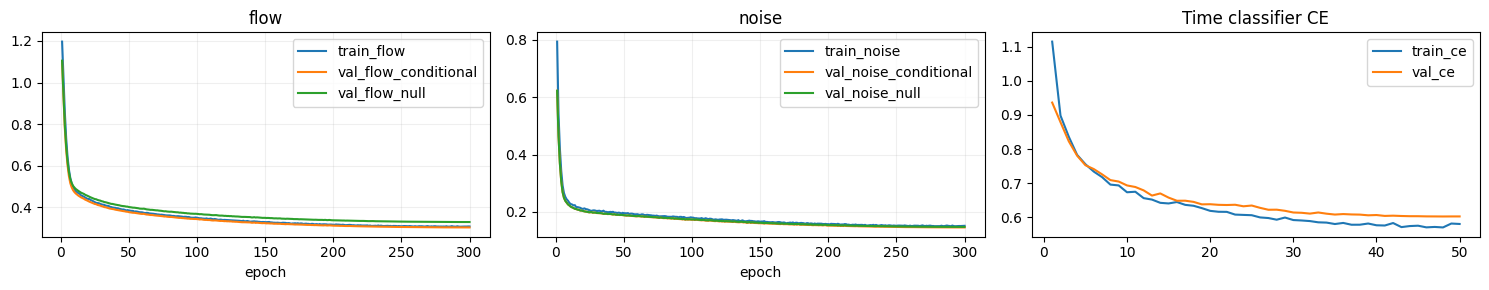

t=0.00: {'ce': 2.354483544921875, 'accuracy': 0.0966}
t=0.05: {'ce': 2.257705261230469, 'accuracy': 0.1612}
t=0.20: {'ce': 1.3454690856933593, 'accuracy': 0.5348}
t=0.50: {'ce': 0.14583542671203614, 'accuracy': 0.9532}
t=0.80: {'ce': 0.06318074426651, 'accuracy': 0.9804}
t=0.95: {'ce': 0.061161655187606814, 'accuracy': 0.9816}
t=1.00: {'ce': 0.0651768871307373, 'accuracy': 0.9812}


In [ ]:
fig,axes=plt.subplots(1,3,figsize=(15,3))
for ax,name in zip(axes[:2],['flow','noise']):
    for key in [f'train_{name}',f'val_{name}_conditional',f'val_{name}_null']:
        ax.plot([r['epoch'] for r in history],[r[key] for r in history],label=key)
    ax.set_title(name); ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=.2)
for key in ['train_ce','val_ce']:
    axes[2].plot([r['epoch'] for r in clf_history],[r[key] for r in clf_history],label=key)
axes[2].set_title('Time classifier CE'); axes[2].legend(); plt.tight_layout(); plt.show()
# 시간별 real validation accuracy. t=0은 label 정보가 없고 t=1은 clean image다.
for tv in [0.,.05,.2,.5,.8,.95,1.]:
    print(f't={tv:.2f}:',evaluate_classifier(classifier,val_loader,fixed_t=tv))

## 7. Guidance를 sampling 코드로 옮기기

아래 함수는 네 방법 모두 같은 Heun ODE를 사용한다. CG는 classifier의 입력 gradient를 얻어야 하므로, 전체 sampling은 `no_grad()`로 실행하되 classifier gradient 계산 안에서만 `enable_grad()`를 사용한다. `inference_mode()`로 감싸면 필요한 gradient 계산이 막힐 수 있다.

01과 같은 $\delta=0.01$부터 $1-\delta$까지 적분한다. 시작 $N(0,I)$는 $p_\delta$의 근사이며 마지막 denoise나 중간 clipping을 추가하지 않는다.

SDE 비교에서는 일관되게 같은 guided velocity와 guided score를 사용한다.

$$\widetilde s_{\mathrm{CG}}=s_{\mathrm{base}}+w\nabla_x\log p_\phi(y\mid x,t),$$

$$\widetilde s_{\mathrm{CFG}}=-\widetilde\epsilon/(1-t),\qquad
\text{drift}=\widetilde v+\kappa(1-t)\widetilde s.$$

Flow 출력으로부터는 $s=(tv-x)/(1-t)$를 사용한다. $g(t)^2=2\kappa(1-t)$는 01과 같다. **$w>1$에서 ODE와 SDE가 같은 marginal distribution을 따른다는 보장은 없다.** Ch.4의 정리는 올바른 probability path의 velocity와 score일 때 적용되며, 강화된 guidance는 heuristic이다.

In [ ]:
def classifier_gradient(x,t,y):
    classifier.eval()
    with torch.enable_grad():
        xin=x.detach().requires_grad_(True)
        log_probs=F.log_softmax(classifier(xin,t),dim=1)
        selected=log_probs.gather(1,y[:,None]).sum()
        grad=torch.autograd.grad(selected,xin)[0]
    return grad.detach()

def prediction_to_fields(pred,x,t,kind):
    if kind=='flow':
        v=pred; s=(t*v-x)/(1-t)
    else:
        v=(x-pred)/t; s=-pred/(1-t)
    return v,s

@torch.no_grad()
def guided_fields(x,t,y,kind,method,w):
    if method in ('baseline','cg'):
        v,s=prediction_to_fields(baselines[kind](x,t),x,t,kind)
        if method=='cg' and w!=0:
            grad=classifier_gradient(x,t,y)
            v=v+w*(1-t)/t*grad
            s=s+w*grad
        return v,s
    if method=='vanilla':
        pred=models[kind](x,t,y)
    else:  # CFG: w=0/1에서는 불필요한 branch 호출을 생략한다.
        null=torch.full_like(y,NULL_LABEL)
        if w==0: pred=models[kind](x,t,null)
        elif w==1: pred=models[kind](x,t,y)
        else:
            pu=models[kind](x,t,null); pc=models[kind](x,t,y)
            pred=pu+w*(pc-pu)
    return prediction_to_fields(pred,x,t,kind)

@torch.no_grad()
def sample(x0,y,kind='flow',method='cfg',w=2.,steps=200,delta=.01,kappa=0.,seed=1234,trace=False):
    assert kind in ('flow','noise') and method in ('baseline','vanilla','cg','cfg')
    assert steps>0 and 0<delta<.5 and w>=0 and kappa>=0
    assert y.shape==(len(x0),) and y.dtype==torch.long
    assert bool(((y>=0)&(y<=9)).all())
    for net in [*baselines.values(),*models.values(),classifier]: net.eval()
    x=x0.to(device).clone(); y=y.to(device)
    grid=torch.linspace(delta,1-delta,steps+1,device=device)
    rng=torch.Generator(device=device).manual_seed(seed)
    keep=set(np.linspace(0,steps,6).round().astype(int).tolist())
    frames=[x.detach().cpu()] if trace else []; times=[float(grid[0])] if trace else []
    for i in range(steps):
        ti,tj=grid[i].item(),grid[i+1].item(); dt=tj-ti
        t=torch.full((len(x),1),ti,device=device)
        v,s=guided_fields(x,t,y,kind,method,w)
        if kappa==0:
            xp=x+dt*v
            vn,_=guided_fields(xp,torch.full_like(t,tj),y,kind,method,w)
            x=x+.5*dt*(v+vn)
        else:
            xi=torch.randn(x.shape,device=device,generator=rng)
            x=x+dt*(v+kappa*(1-ti)*s)+math.sqrt(2*kappa*(1-ti)*dt)*xi
        if trace and i+1 in keep:
            frames.append(x.detach().cpu()); times.append(tj)
    if not torch.isfinite(x).all(): raise RuntimeError('생성 결과에 NaN/Inf가 있습니다.')
    return (x,times,torch.stack(frames)) if trace else x

def report_pixels(x):
    print('raw min/max:',x.min().item(),x.max().item(),
          'outside [-1,1]:',f'{100*((x<-1)|(x>1)).float().mean().item():.2f}%')

# 학습된 모델을 고정한다. classifier input gradient는 계속 계산할 수 있다.
for net in [*baselines.values(),*models.values(),classifier]: net.eval().requires_grad_(False)

## 8. 같은 initial noise에서 네 방법 비교하기

각 행의 target label은 위에서부터 0–9다. 같은 열은 label이 달라도 같은 initial noise를 사용한다. Baseline은 label을 무시하므로 각 행이 반복되는 것이 정상이다. Flow와 Noise는 각각 별도로 비교한다.

CG의 w=0은 01 baseline이고, CFG의 w=0은 02의 null branch다. 두 방법의 차이는 classifier 유무뿐 아니라 생성 모델의 학습 구성도 포함한다. 최종 결론에서는 이 차이를 함께 설명한다.

flow baseline w= 0.0
raw min/max: -2.241504669189453 2.317037582397461 outside [-1,1]: 33.00%


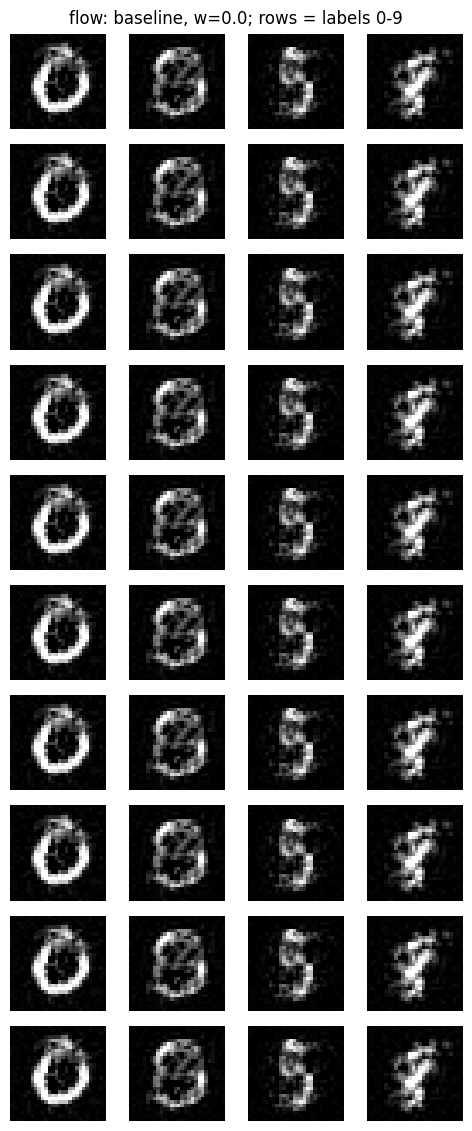

flow vanilla w= 1.0
raw min/max: -2.3501086235046387 2.6493537425994873 outside [-1,1]: 36.49%


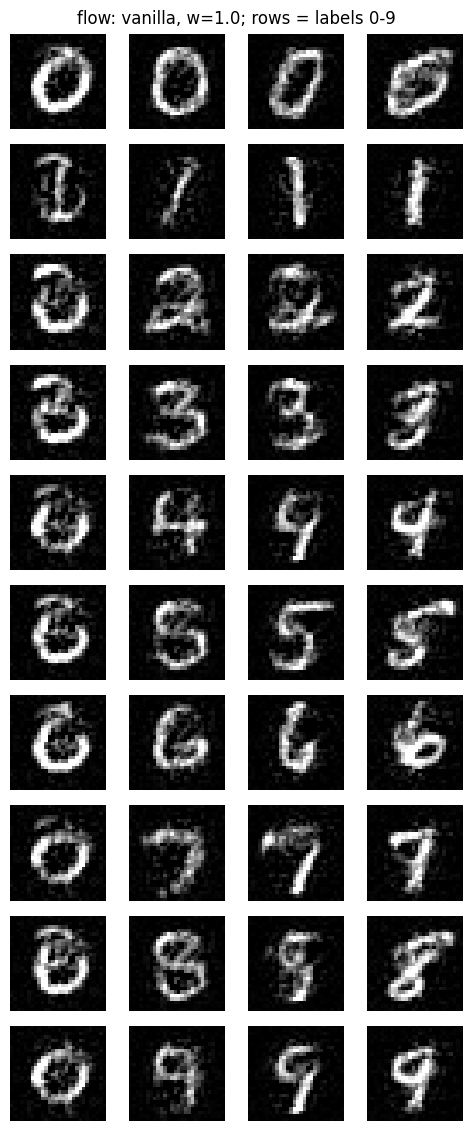

flow cg w= 2.0
raw min/max: -2.3742213249206543 2.831973075866699 outside [-1,1]: 37.23%


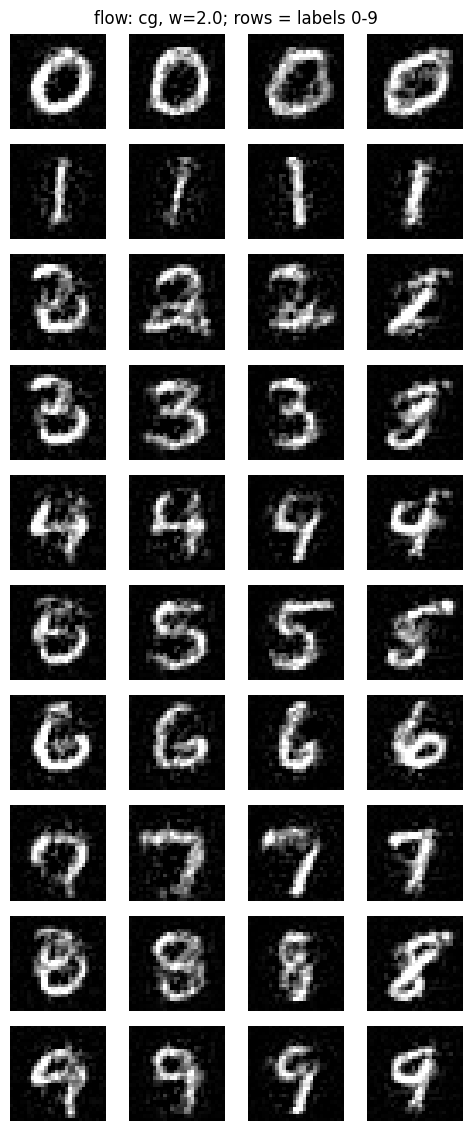

flow cfg w= 2.0
raw min/max: -2.451777458190918 3.0398144721984863 outside [-1,1]: 38.79%


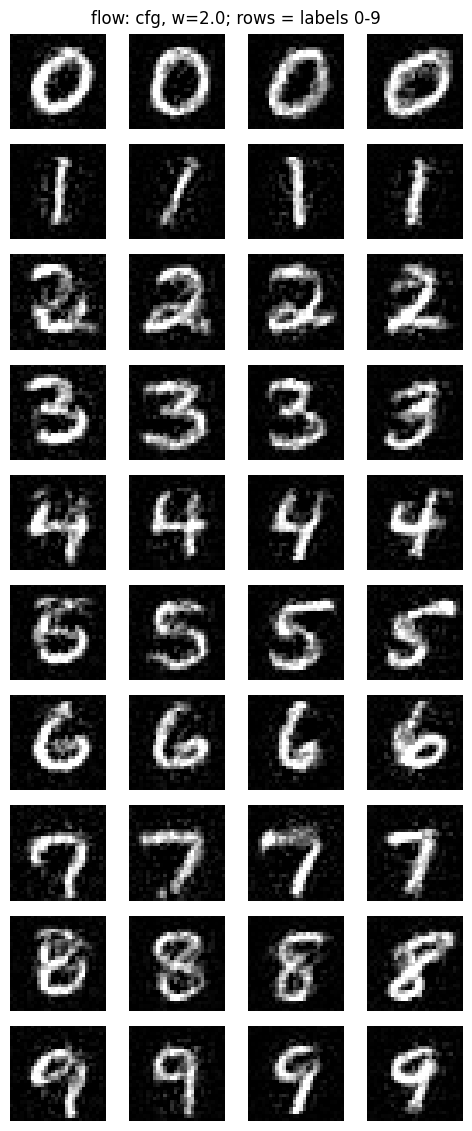

noise baseline w= 0.0
raw min/max: -4.156575679779053 4.473984718322754 outside [-1,1]: 42.51%


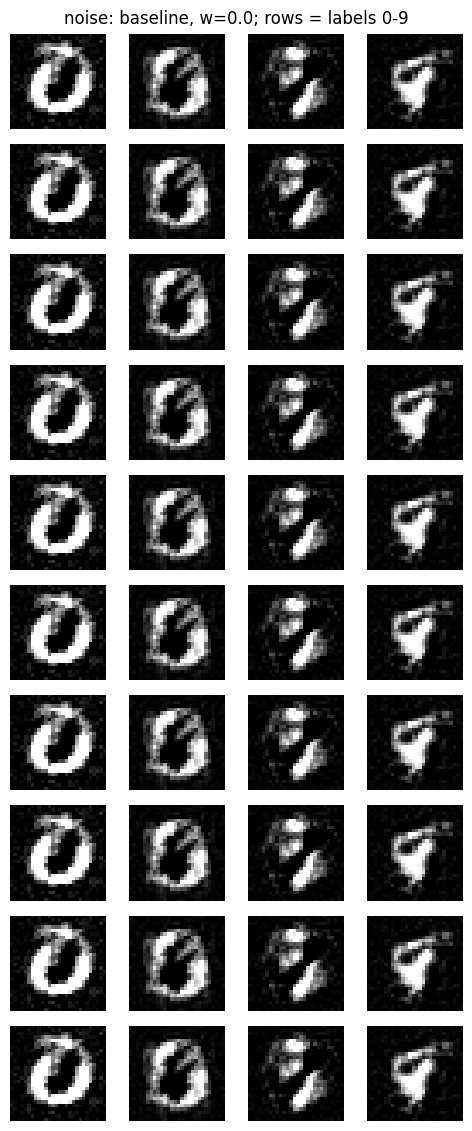

noise vanilla w= 1.0
raw min/max: -4.405634880065918 3.8774094581604004 outside [-1,1]: 38.73%


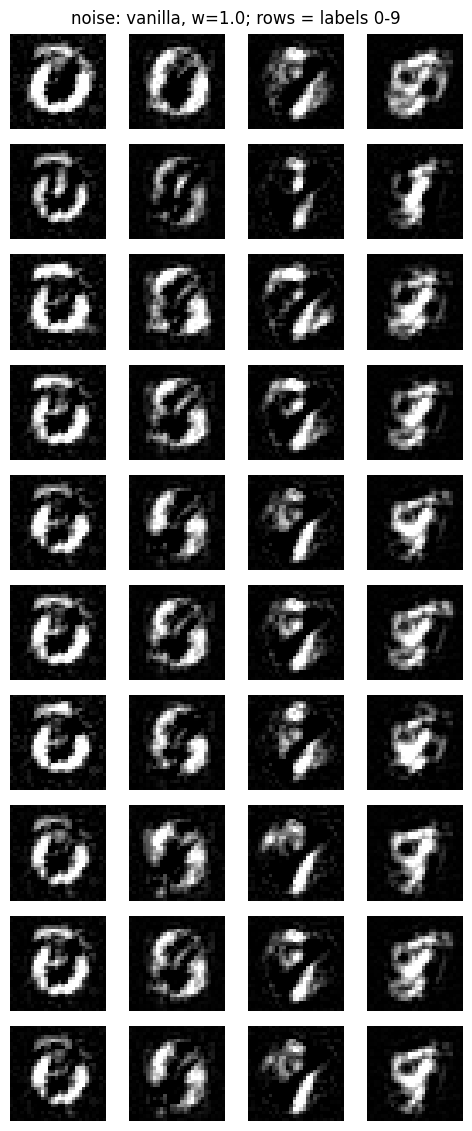

noise cg w= 2.0
raw min/max: -4.802249431610107 5.279191970825195 outside [-1,1]: 42.89%


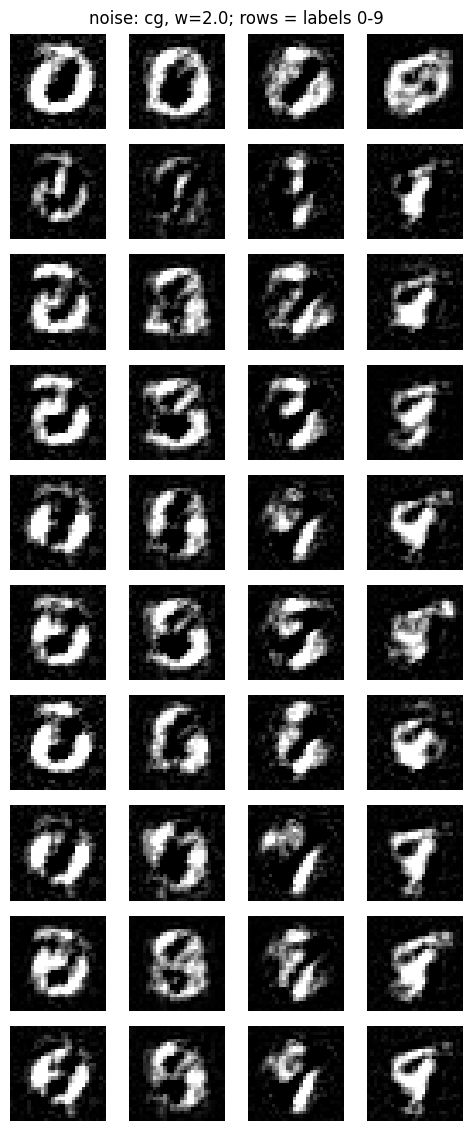

noise cfg w= 2.0
raw min/max: -5.095306396484375 5.218574047088623 outside [-1,1]: 43.05%


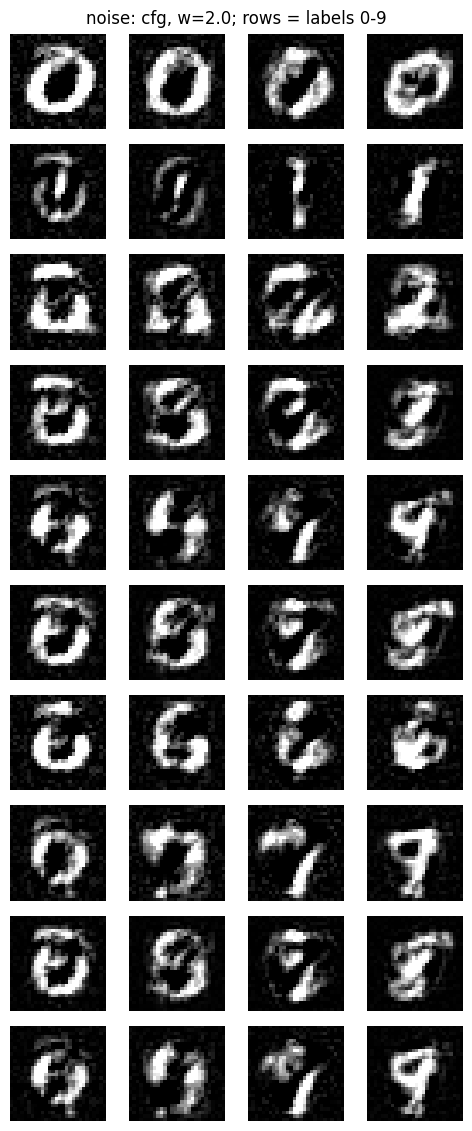

In [ ]:
COLS=4
fixed_rng=torch.Generator().manual_seed(999)
column_noise=torch.randn((COLS,784),generator=fixed_rng)
x0=column_noise.repeat(10,1).to(device)
y_grid=torch.arange(10,device=device).repeat_interleave(COLS)
for kind in ['flow','noise']:
    for method,w in [('baseline',0.),('vanilla',1.),('cg',2.),('cfg',2.)]:
        samples=sample(x0,y_grid,kind=kind,method=method,w=w)
        print(kind,method,'w=',w); report_pixels(samples)
        show_grid(samples,f'{kind}: {method}, w={w}; rows = labels 0-9',cols=COLS)

### 8.1 Guidance strength만 바꾸기

모델과 initial noise, label, ODE solver를 고정하고 w만 바꾼다. 숫자 식별 가능성·획과 배경의 선명함·다양성을 관찰한다. 큰 w가 항상 좋은 결과를 보장하지 않으며, saturation이나 형태 왜곡이 생길 수도 있다. 다른 label이나 더 많은 sample로 결론을 확인한다.

flow cg w= 0.0
raw min/max: -2.480236768722534 3.2587380409240723 outside [-1,1]: 35.55%


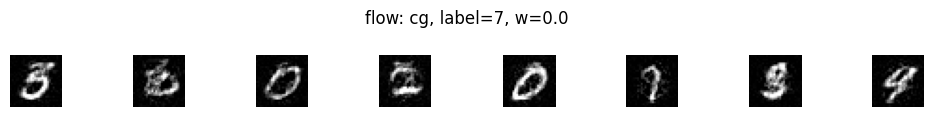

flow cg w= 1.0
raw min/max: -1.979659080505371 2.4720962047576904 outside [-1,1]: 37.42%


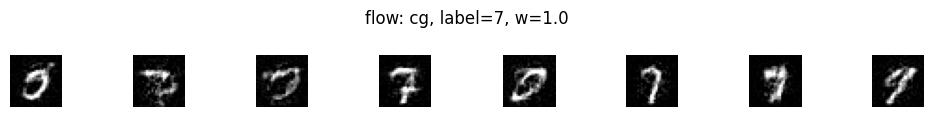

flow cg w= 2.0
raw min/max: -2.0504281520843506 2.3772003650665283 outside [-1,1]: 39.21%


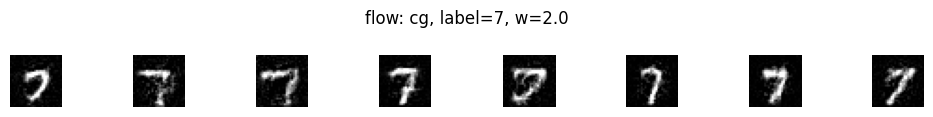

flow cg w= 4.0
raw min/max: -2.1438729763031006 2.698288679122925 outside [-1,1]: 41.77%


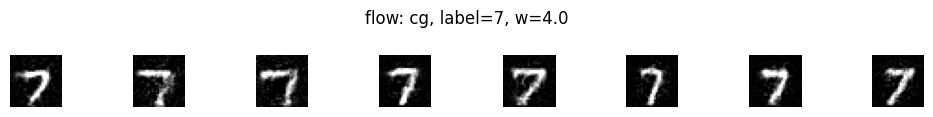

flow cg w= 6.0
raw min/max: -2.1532716751098633 2.886972665786743 outside [-1,1]: 43.48%


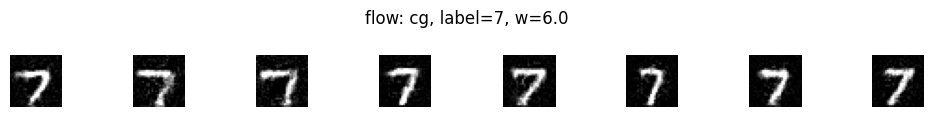

flow cg w= 8.0
raw min/max: -2.1628637313842773 3.025703191757202 outside [-1,1]: 44.32%


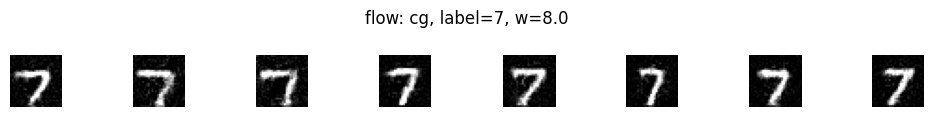

flow cfg w= 0.0
raw min/max: -2.2310268878936768 3.272111654281616 outside [-1,1]: 35.25%


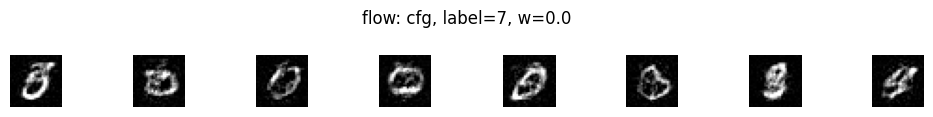

flow cfg w= 1.0
raw min/max: -1.8933011293411255 2.5312864780426025 outside [-1,1]: 38.42%


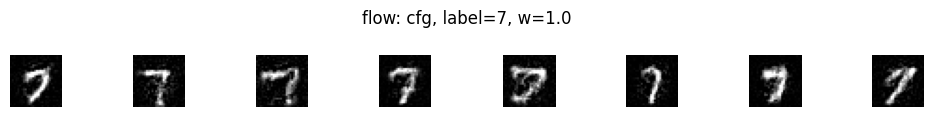

flow cfg w= 2.0
raw min/max: -2.0175390243530273 2.7310943603515625 outside [-1,1]: 41.41%


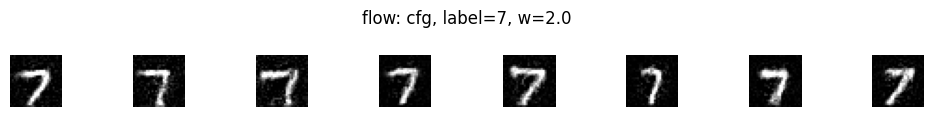

flow cfg w= 4.0
raw min/max: -2.746551036834717 3.8815479278564453 outside [-1,1]: 46.35%


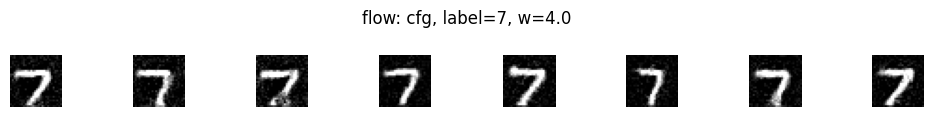

flow cfg w= 6.0
raw min/max: -3.3392059803009033 4.771327495574951 outside [-1,1]: 49.47%


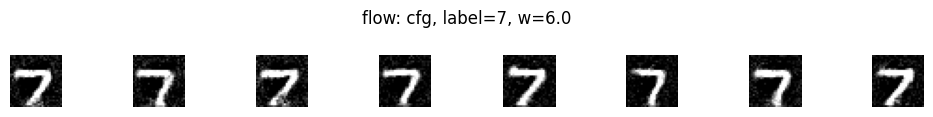

flow cfg w= 8.0
raw min/max: -4.517243385314941 5.519676685333252 outside [-1,1]: 49.98%


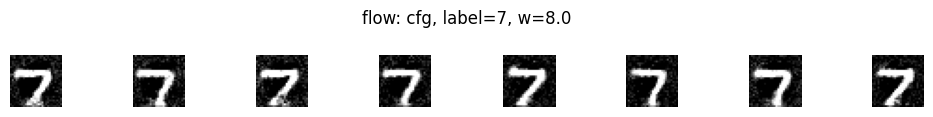

noise cg w= 0.0
raw min/max: -3.837489128112793 4.944512367248535 outside [-1,1]: 37.91%


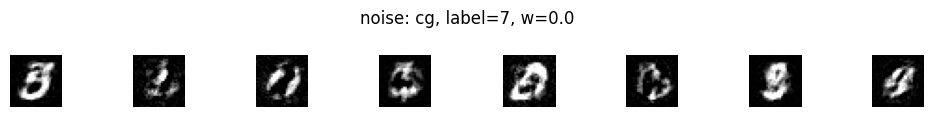

noise cg w= 1.0
raw min/max: -3.848734140396118 3.2471561431884766 outside [-1,1]: 36.03%


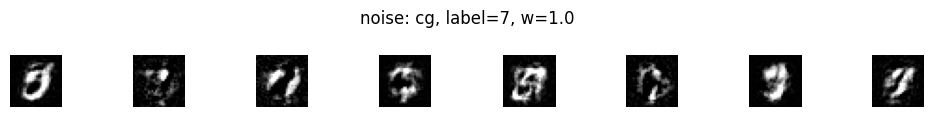

noise cg w= 2.0
raw min/max: -3.9714627265930176 3.238738536834717 outside [-1,1]: 37.83%


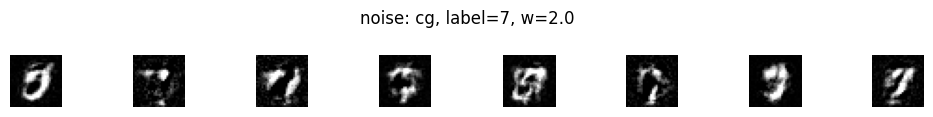

noise cg w= 4.0
raw min/max: -4.2072434425354 3.2582244873046875 outside [-1,1]: 42.38%


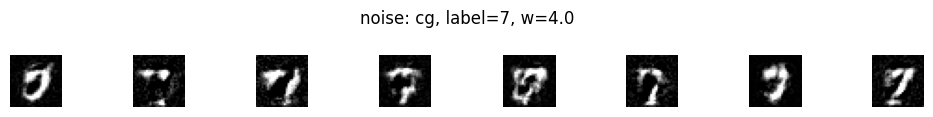

noise cg w= 6.0
raw min/max: -4.483015060424805 3.329953193664551 outside [-1,1]: 45.58%


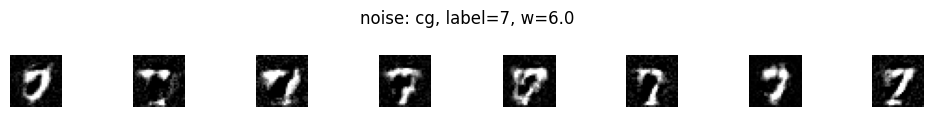

noise cg w= 8.0
raw min/max: -4.695727825164795 3.642479419708252 outside [-1,1]: 47.19%


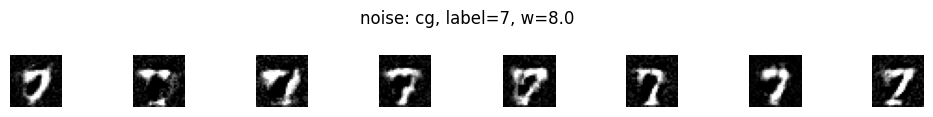

noise cfg w= 0.0
raw min/max: -3.3654634952545166 3.6323180198669434 outside [-1,1]: 33.74%


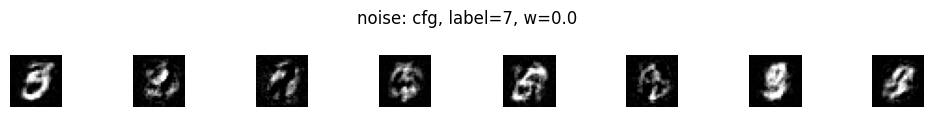

noise cfg w= 1.0
raw min/max: -3.446658134460449 3.477375030517578 outside [-1,1]: 35.60%


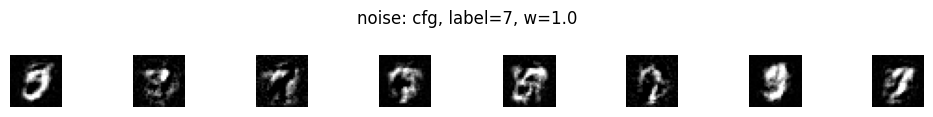

noise cfg w= 2.0
raw min/max: -3.845766305923462 3.7840516567230225 outside [-1,1]: 42.11%


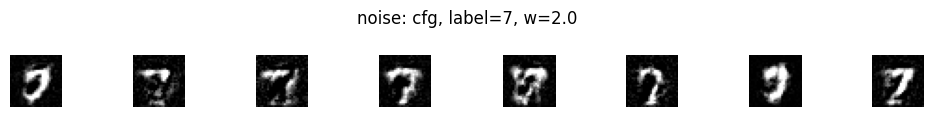

noise cfg w= 4.0
raw min/max: -4.623837947845459 4.763119697570801 outside [-1,1]: 48.33%


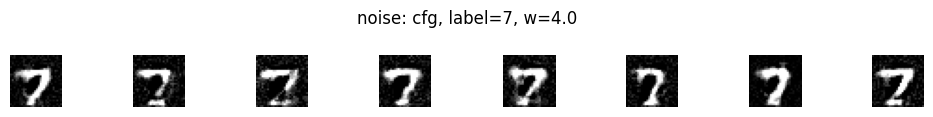

noise cfg w= 6.0
raw min/max: -5.354348182678223 5.729856967926025 outside [-1,1]: 49.89%


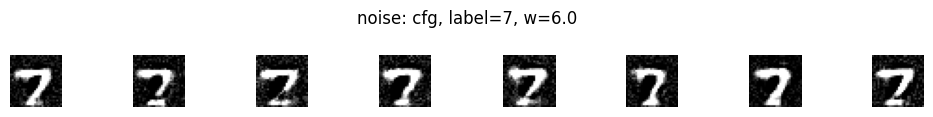

noise cfg w= 8.0
raw min/max: -6.0974321365356445 6.7101521492004395 outside [-1,1]: 50.67%


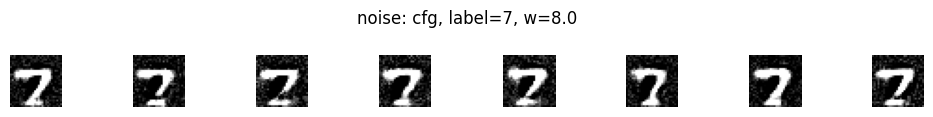

In [ ]:
TARGET_LABEL=7
SWEEP_SAMPLES=8
sweep_x=torch.randn((SWEEP_SAMPLES,784),generator=torch.Generator().manual_seed(1001)).to(device)
sweep_y=torch.full((SWEEP_SAMPLES,),TARGET_LABEL,device=device,dtype=torch.long)
for kind in ['flow','noise']:
    for method in ['cg','cfg']:
        for w in [0.,1.,2.,4., 6., 8.]:
            samples=sample(sweep_x,sweep_y,kind=kind,method=method,w=w)
            print(kind,method,'w=',w); report_pixels(samples)
            show_grid(samples,f'{kind}: {method}, label={TARGET_LABEL}, w={w}',cols=SWEEP_SAMPLES)

### 8.2 Pretrained classifier로 guidance strength 평가하기

눈으로 구분하기 어려운 차이를 **label 일치도**로 확인한다. CG에 사용한 TimeClassifier와 독립적인 공개 CNN [cmaeti/mnist-cnn](https://huggingface.co/cmaeti/mnist-cnn)을 사용한다(Apache-2.0). 모델과 [전처리 코드](https://huggingface.co/cmaeti/mnist-cnn/blob/dd00ea6fffad752ea2dd9cebceebd95fa9cfbc95/demo/app.py)의 revision을 고정했다. 외부 Python 코드를 실행하지 않고 safetensors weights만 읽는다.

먼저 공식 MNIST test 10,000장에서 evaluator의 accuracy를 직접 확인한다. 이는 평가 도구의 sanity check이며 생성 모델을 고르는 test loss가 아니다. 공개 모델의 전체 training provenance를 독립 검증한 것은 아니므로, 이 점수도 재현 확인값으로 해석한다. 98% 미만이면 평가를 중단한다.

그다음 **각 label 100개, 총 1,000개의 독립 initial noise**를 생성하고 모든 방법과 w에서 동일하게 재사용한다. Flow/Noise × CG/CFG × w=0,1,2,4,6,8을 비교한다. w=0의 CG는 01 baseline, CFG는 02 null branch이며 CFG w=1은 vanilla conditional이다. Heun 200 step, delta=0.01은 8.1과 동일하다.

- **Target accuracy:** 요청한 label과 evaluator 예측의 일치 비율. class별 표와 95% Wilson interval도 표시한다.
- **Paired Δ vs w=4:** 같은 initial noise끼리 accuracy 차이를 계산하고 label별 bootstrap으로 95% interval을 구한다. 이는 sampling 불확실성만 나타내며 training seed나 evaluator 편향은 포함하지 않는다. 여러 w 비교는 탐색적 분석이다.
- **Within-class feature spread:** evaluator의 128차원 feature에서 class 내부 분산을 측정한다. 감소하면 다양성 축소 가능성이 있지만, artifact가 늘어도 증가하므로 품질 점수가 아니다.
- **Raw out-of-range / clipping amount:** 표시 전 pixel이 [-1,1] 밖에 있는 비율과 평균 초과량. 배경의 작은 overshoot도 포함되므로 이것만으로 실패라고 판단하지 않는다.

Evaluator는 표시된 이미지와 일치하도록 **생성 완료 후에만** [-1,1] clipping → [0,1] → (x−0.1307)/0.3081 전처리를 사용한다. Sampling 중에는 clipping하지 않는다. Accuracy와 confidence가 높아도 획의 자연스러움이나 다양성이 보장되지는 않는다. 가장 높은 점수를 자동으로 '최고 품질'로 선택하지 않는다.

학습된 모델과 7번 sampling 함수가 메모리에 있는 상태에서 아래 세 셀만 실행한다. 각 설정의 raw images와 예측값을 Drive에 저장하므로 중단 후 완료한 설정은 재사용한다. 모델 weights·sampler·평가 설정이 달라지면 별도 cache를 사용한다.


In [ ]:
# 8.2-A: evaluator 준비와 real MNIST sanity check (재학습 없음)
import hashlib, inspect, sys, subprocess
import pandas as pd
from IPython.display import display
try:
    from safetensors.torch import load_file
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'safetensors'])
    from safetensors.torch import load_file
import urllib.request

EVAL_REPO = 'cmaeti/mnist-cnn'
EVAL_REV = 'dd00ea6fffad752ea2dd9cebceebd95fa9cfbc95'
EVAL_WEIGHTS = RUN_DIR / 'evaluation_tools/mnist-cnn.safetensors'
EVAL_WEIGHTS.parent.mkdir(parents=True, exist_ok=True)
if not EVAL_WEIGHTS.exists():
    urllib.request.urlretrieve(
        f'https://huggingface.co/{EVAL_REPO}/resolve/{EVAL_REV}/mnist-cnn.safetensors',
        EVAL_WEIGHTS.with_suffix('.download'))
    os.replace(EVAL_WEIGHTS.with_suffix('.download'), EVAL_WEIGHTS)
EVAL_WEIGHT_SHA = hashlib.sha256(EVAL_WEIGHTS.read_bytes()).hexdigest()
assert EVAL_WEIGHT_SHA == 'ee8326a4b31466822379c10921f77d2e56dc6dea6a35fc2c49230e3393ae00e2', 'Evaluator weights checksum mismatch'

# Architecture adapted from the source repository's demo/app.py (Apache-2.0).
class EvaluationCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1,32,3,1)
        self.conv2 = nn.Conv2d(32,64,3,1)
        self.dropout1 = nn.Dropout(.25)
        self.dropout2 = nn.Dropout(.5)
        self.fc1 = nn.Linear(9216,128)
        self.fc2 = nn.Linear(128,10)
    def forward(self,x,return_features=False):
        x=F.relu(self.conv1(x)); x=F.relu(self.conv2(x))
        x=self.dropout1(F.max_pool2d(x,2)).flatten(1)
        features=F.relu(self.fc1(x))
        logits=self.fc2(self.dropout2(features))
        return (logits,features) if return_features else logits

evaluator=EvaluationCNN().to(device)
evaluator.load_state_dict(load_file(str(EVAL_WEIGHTS)),strict=True)
evaluator.eval().requires_grad_(False)

@torch.no_grad()
def eval_images(raw):
    # Our images are [-1,1]; classifier training used MNIST mean/std on [0,1].
    x=(raw.reshape(-1,1,28,28).to(device).clamp(-1,1)+1)/2
    return evaluator((x-.1307)/.3081,return_features=True)

eval_test_correct=torch.zeros(10,dtype=torch.long)
eval_test_total=torch.zeros(10,dtype=torch.long)
for real,label in test_loader:
    logits,_=eval_images(real)
    pred=logits.argmax(1).cpu(); label=label.cpu()
    eval_test_total+=torch.bincount(label,minlength=10)
    eval_test_correct+=torch.bincount(label[pred==label],minlength=10)
EVAL_REAL_ACC=(eval_test_correct.sum()/eval_test_total.sum()).item()
print(f'Pretrained evaluator: MNIST test accuracy = {EVAL_REAL_ACC:.2%}')
display(pd.DataFrame({'label':range(10),'real_test_accuracy':(eval_test_correct/eval_test_total).numpy()}))
assert EVAL_REAL_ACC>=.98, 'Evaluator sanity check failed; stop and check weights/preprocessing.'


Pretrained evaluator: MNIST test accuracy = 99.17%


,label,real_test_accuracy
0,0,0.995918
1,1,0.997357
2,2,0.994186
3,3,0.994059
4,4,0.992872
5,5,0.991031
6,6,0.986430
7,7,0.991245
8,8,0.990760
9,9,0.982161


In [ ]:
# 8.2-B: 고정 initial noise에서 생성하고 cache 저장. weights는 업데이트하지 않는다.
EVAL_PER_CLASS=100
EVAL_WS=[0.,1.,2.,4.,6.,8.]
EVAL_KINDS=['flow','noise']
EVAL_METHODS=['cg','cfg']
EVAL_SEED=20261111
EVAL_BATCH=250
EVAL_STEPS=200
EVAL_DELTA=.01
assert EVAL_PER_CLASS>=2 and 4. in EVAL_WS
for name in ['models','baselines','classifier','sample']:
    assert name in globals(), f'{name}가 없습니다. 학습된 모델 복원 및 7번 셀을 먼저 실행하세요.'

# 모델/함수/설정이 바뀐 뒤 이전 결과를 잘못 읽지 않도록 fingerprint를 저장한다.
eval_hash=hashlib.sha256()
for name,net in sorted({**{'base_'+k:v for k,v in baselines.items()},
                        **{'cond_'+k:v for k,v in models.items()},'classifier':classifier}.items()):
    net.eval().requires_grad_(False)
    for key,value in sorted(net.state_dict().items()):
        eval_hash.update((name+key).encode())
        eval_hash.update(value.detach().cpu().contiguous().numpy().tobytes())
for fn in [sample,guided_fields,prediction_to_fields,classifier_gradient]:
    eval_hash.update(inspect.getsource(fn).encode())
eval_settings=dict(version='guidance_eval_v1',per_class=EVAL_PER_CLASS,seed=EVAL_SEED,
                   steps=EVAL_STEPS,delta=EVAL_DELTA,batch=EVAL_BATCH,kappa=0.,
                   evaluator_repo=EVAL_REPO,evaluator_revision=EVAL_REV,
                   evaluator_sha256=EVAL_WEIGHT_SHA,real_test_accuracy=EVAL_REAL_ACC,
                   model_sampler_sha256=eval_hash.hexdigest())
EVAL_TAG=hashlib.sha256(json.dumps(eval_settings,sort_keys=True).encode()).hexdigest()[:16]
EVAL_DIR=RUN_DIR/'evaluation_8_2'/EVAL_TAG
EVAL_DIR.mkdir(parents=True,exist_ok=True)
(EVAL_DIR/'settings.json').write_text(json.dumps(eval_settings,indent=2))
eval_labels=torch.arange(10).repeat_interleave(EVAL_PER_CLASS)
eval_x0=torch.randn((len(eval_labels),784),generator=torch.Generator().manual_seed(EVAL_SEED))
eval_records={}
for kind in EVAL_KINDS:
    for method in EVAL_METHODS:
        for w in EVAL_WS:
            path=EVAL_DIR/f'{kind}_{method}_w{w:g}.pt'
            if path.exists():
                record=torch.load(path,map_location='cpu',weights_only=True)
                assert torch.equal(record['labels'],eval_labels)
            else:
                chunks=[]
                for start in range(0,len(eval_labels),EVAL_BATCH):
                    chunks.append(sample(eval_x0[start:start+EVAL_BATCH].to(device),
                        eval_labels[start:start+EVAL_BATCH].to(device),kind=kind,method=method,w=w,
                        steps=EVAL_STEPS,delta=EVAL_DELTA,kappa=0.).detach().cpu())
                raw=torch.cat(chunks)
                probs=[]; feats=[]
                for batch in raw.split(EVAL_BATCH):
                    logits,features=eval_images(batch)
                    probs.append(logits.softmax(1).cpu()); feats.append(features.cpu())
                record=dict(raw=raw,labels=eval_labels.clone(),probabilities=torch.cat(probs),
                            features=torch.cat(feats))
                atomic_save(record,path)
            eval_records[(kind,method,w)]=record
            acc=(record['probabilities'].argmax(1)==eval_labels).float().mean().item()
            print(f'{kind:5s} {method:3s} w={w:g}: target accuracy={acc:.1%}',flush=True)
print('Saved evaluation:',EVAL_DIR)


flow  cg  w=0: target accuracy=10.3%
flow  cg  w=1: target accuracy=69.4%
flow  cg  w=2: target accuracy=92.9%
flow  cg  w=4: target accuracy=99.1%
flow  cg  w=6: target accuracy=99.9%
flow  cg  w=8: target accuracy=100.0%
flow  cfg w=0: target accuracy=11.5%
flow  cfg w=1: target accuracy=88.5%
flow  cfg w=2: target accuracy=100.0%
flow  cfg w=4: target accuracy=100.0%
flow  cfg w=6: target accuracy=100.0%
flow  cfg w=8: target accuracy=100.0%
noise cg  w=0: target accuracy=9.2%
noise cg  w=1: target accuracy=43.1%
noise cg  w=2: target accuracy=64.4%
noise cg  w=4: target accuracy=85.4%
noise cg  w=6: target accuracy=92.8%
noise cg  w=8: target accuracy=94.6%
noise cfg w=0: target accuracy=10.1%
noise cfg w=1: target accuracy=36.5%
noise cfg w=2: target accuracy=68.5%
noise cfg w=4: target accuracy=85.7%
noise cfg w=6: target accuracy=91.9%
noise cfg w=8: target accuracy=92.8%
Saved evaluation: /content/drive/MyDrive/MNIST_Guidance/run_v1/evaluation_8_2/3d18797363994231


Accuracy/probability/range columns: 0–1. Paired delta: percentage points.


,kind,method,w,accuracy,ci_low,ci_high,label7_accuracy,target_probability,feature_spread,out_of_range,clipping_amount
0,flow,cg,0.0,0.103,0.0857,0.1234,0.13,0.1086,0.4438,0.3570,0.0404
1,flow,cg,1.0,0.694,0.6647,0.7218,0.71,0.6166,0.2958,0.3568,0.0405
2,flow,cg,2.0,0.929,0.9114,0.9433,0.98,0.8767,0.2868,0.3705,0.0458
3,flow,cg,4.0,0.991,0.9830,0.9953,1.00,0.9809,0.2600,0.3914,0.0573
4,flow,cg,6.0,0.999,0.9944,0.9998,1.00,0.9939,0.2457,0.4064,0.0686
5,flow,cg,8.0,1.000,0.9962,1.0000,1.00,0.9975,0.2370,0.4175,0.0791
6,flow,cfg,0.0,0.115,0.0967,0.1363,0.13,0.1080,0.2766,0.3505,0.0388
7,flow,cfg,1.0,0.885,0.8637,0.9033,0.90,0.8022,0.2742,0.3587,0.0404
8,flow,cfg,2.0,1.000,0.9962,1.0000,1.00,0.9915,0.2545,0.3863,0.0531
9,flow,cfg,4.0,1.000,0.9962,1.0000,1.00,0.9998,0.2028,0.4354,0.0973


Per-label target accuracy:


label                0     1     2     3     4     5     6     7     8     9
kind  method w                                                              
flow  cfg    0.0  0.08  0.05  0.10  0.25  0.10  0.08  0.06  0.13  0.13  0.17
             1.0  0.97  0.97  0.92  0.91  0.88  0.86  0.87  0.90  0.76  0.81
             2.0  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
             4.0  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
             6.0  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
             8.0  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
      cg     0.0  0.10  0.09  0.12  0.20  0.10  0.04  0.07  0.13  0.08  0.10
             1.0  0.81  0.82  0.68  0.80  0.58  0.61  0.62  0.71  0.61  0.70
             2.0  0.99  0.98  0.95  0.99  0.89  0.83  0.93  0.98  0.87  0.88
             4.0  1.00  1.00  0.99  1.00  0.99  0.97  1.00  1.00  0.99  0.97
             6.0  1.00  1.00  1.00  1.00  1.00  0.99  1.00  1.00  1.00  1.00
             8.0  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
noise cfg    0.0  0.07  0.05  0.11  0.25  0.08  0.08  0.02  0.08  0.14  0.13
             1.0  0.55  0.36  0.41  0.57  0.32  0.17  0.28  0.48  0.20  0.31
             2.0  0.87  0.85  0.86  0.86  0.54  0.36  0.84  0.89  0.29  0.49
             4.0  1.00  1.00  0.99  0.99  0.83  0.63  0.98  1.00  0.55  0.60
             6.0  1.00  1.00  1.00  1.00  0.98  0.75  1.00  1.00  0.76  0.70
             8.0  1.00  1.00  1.00  1.00  0.98  0.76  1.00  1.00  0.83  0.71
      cg     0.0  0.15  0.05  0.12  0.17  0.07  0.06  0.03  0.10  0.06  0.11
             1.0  0.64  0.32  0.51  0.69  0.27  0.39  0.26  0.45  0.35  0.43
             2.0  0.80  0.59  0.76  0.86  0.41  0.54  0.48  0.71  0.54  0.75
             4.0  0.98  0.81  0.87  0.97  0.76  0.79  0.80  0.94  0.75  0.87
             6.0  0.99  0.94  0.92  1.00  0.90  0.90  0.89  0.98  0.84  0.92
             8.0  1.00  0.96  0.96  1.00  0.94  0.91  0.93  0.98  0.84  0.94

Paired accuracy change relative to w=4 (95% bootstrap interval):


,kind,method,w,delta_pp,ci_low_pp,ci_high_pp,improved,regressed
0,flow,cg,0.0,-88.800003,-90.700,-86.800,0,888
1,flow,cg,1.0,-29.700001,-32.500,-26.900,0,297
2,flow,cg,2.0,-6.200000,-7.900,-4.700,0,62
3,flow,cg,4.0,0.000000,0.000,0.000,0,0
4,flow,cg,6.0,0.800000,0.300,1.400,8,0
5,flow,cg,8.0,0.900000,0.400,1.500,9,0
6,flow,cfg,0.0,-88.500000,-90.400,-86.600,0,885
7,flow,cfg,1.0,-11.500000,-13.500,-9.700,0,115
8,flow,cfg,2.0,0.000000,0.000,0.000,0,0
9,flow,cfg,4.0,0.000000,0.000,0.000,0,0


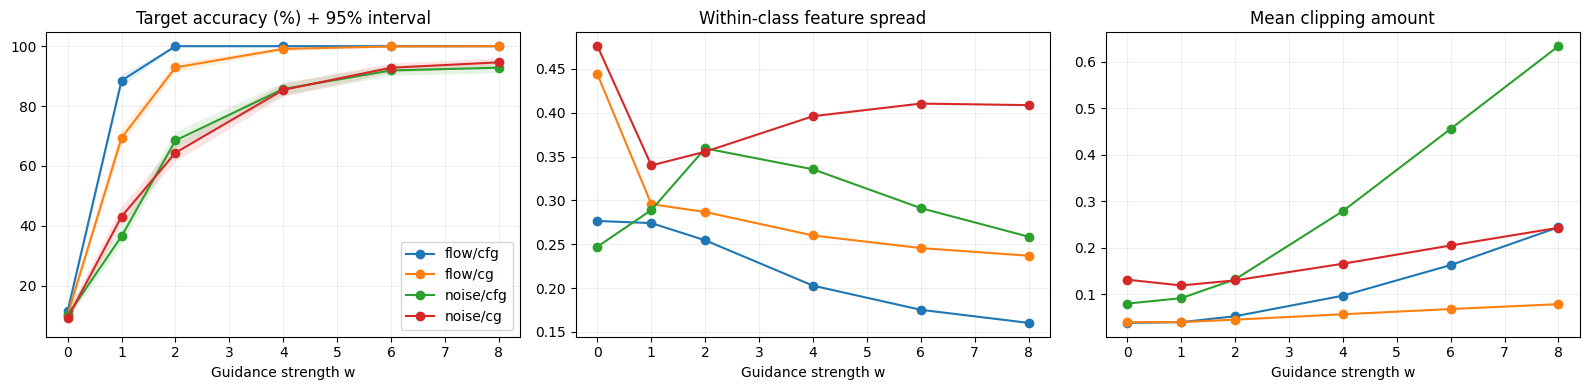

Flow CFG: w=4와 비교한 w=6,8의 interval이 0을 포함하면 이 sample에서 명확한 향상 근거가 약합니다.
Accuracy는 label 인식 지표이며 시각적 품질 점수가 아닙니다. 같은 sample의 획/배경/다양성도 함께 확인하세요.


In [ ]:
# 8.2-C: 요약표, 숫자별 accuracy, paired 변화량, 진단 그래프

def wilson_interval(correct,n):
    p=correct/n; z=1.96; d=1+z*z/n
    center=(p+z*z/(2*n))/d
    half=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return center-half,center+half

rows=[]; per_class=[]; paired=[]
for (kind,method,w),r in eval_records.items():
    probs=r['probabilities']; hit=(probs.argmax(1)==eval_labels)
    lo,hi=wilson_interval(hit.sum().item(),len(hit))
    spread=torch.stack([r['features'][eval_labels==y].var(0,unbiased=False).mean()
                        for y in range(10)]).mean().item()
    rows.append(dict(kind=kind,method=method,w=w,accuracy=hit.float().mean().item(),
        ci_low=lo,ci_high=hi,label7_accuracy=hit[eval_labels==7].float().mean().item(),
        target_probability=probs[torch.arange(len(hit)),eval_labels].mean().item(),
        feature_spread=spread,out_of_range=(r['raw'].abs()>1).float().mean().item(),
        clipping_amount=(r['raw']-r['raw'].clamp(-1,1)).abs().mean().item()))
    for y in range(10):
        per_class.append(dict(kind=kind,method=method,w=w,label=y,
            accuracy=hit[eval_labels==y].float().mean().item()))
    base=eval_records[(kind,method,4.)]
    base_hit=base['probabilities'].argmax(1)==eval_labels
    delta=(hit.float()-base_hit.float()).reshape(10,EVAL_PER_CLASS).numpy()
    rng=np.random.default_rng(42)
    boot=np.zeros(2000)
    for y in range(10):
        indices=rng.integers(0,EVAL_PER_CLASS,size=(2000,EVAL_PER_CLASS))
        boot+=delta[y][indices].mean(axis=1)/10
    low,high=np.quantile(boot,[.025,.975])
    paired.append(dict(kind=kind,method=method,w=w,delta_pp=100*delta.mean(),
        ci_low_pp=100*low,ci_high_pp=100*high,
        improved=int((hit & ~base_hit).sum()),regressed=int((~hit & base_hit).sum())))
eval_summary=pd.DataFrame(rows)
eval_by_label=pd.DataFrame(per_class)
eval_paired=pd.DataFrame(paired)
for filename,df in [('summary',eval_summary),('per_label',eval_by_label),('paired_vs_w4',eval_paired)]:
    df.to_csv(EVAL_DIR/f'{filename}.csv',index=False)
print('Accuracy/probability/range columns: 0–1. Paired delta: percentage points.')
display(eval_summary.round(4))
print('Per-label target accuracy:')
display(eval_by_label.pivot(index=['kind','method','w'],columns='label',values='accuracy').round(3))
print('Paired accuracy change relative to w=4 (95% bootstrap interval):')
display(eval_paired.round(3))
fig,axes=plt.subplots(1,3,figsize=(16,4))
for (kind,method),df in eval_summary.groupby(['kind','method']):
    df=df.sort_values('w'); label=f'{kind}/{method}'
    axes[0].plot(df.w,100*df.accuracy,'o-',label=label)
    axes[0].fill_between(df.w,100*df.ci_low,100*df.ci_high,alpha=.12)
    axes[1].plot(df.w,df.feature_spread,'o-',label=label)
    axes[2].plot(df.w,df.clipping_amount,'o-',label=label)
for ax,title in zip(axes,['Target accuracy (%) + 95% interval','Within-class feature spread','Mean clipping amount']):
    ax.set(xlabel='Guidance strength w',title=title); ax.grid(alpha=.2)
axes[0].legend();plt.tight_layout();plt.show()
print('Flow CFG: w=4와 비교한 w=6,8의 interval이 0을 포함하면 이 sample에서 명확한 향상 근거가 약합니다.')
print('Accuracy는 label 인식 지표이며 시각적 품질 점수가 아닙니다. 같은 sample의 획/배경/다양성도 함께 확인하세요.')


## 9. Trajectory와 ODE/SDE 비교

최종 이미지뿐 아니라 같은 시작점에서 중간 이미지가 어떻게 달라지는지 확인한다. ODE도 곡선 trajectory를 가질 수 있으며, SDE는 매 step 새로운 random increment가 추가된다. 아래는 동일 CFG 모델·label·w를 고정한 비교다. Heun 200 step과 Euler–Maruyama 400 step은 field 평가 횟수가 400회로 같다. CFG w=2에서는 각 평가마다 생성 모델을 두 번 호출한다. Solver와 step 수가 다르므로 kappa만의 순수한 효과라고 해석하지 않는다.

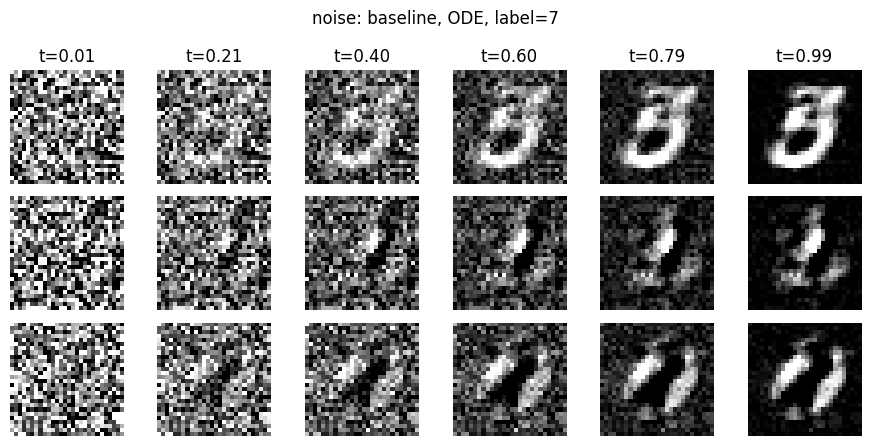

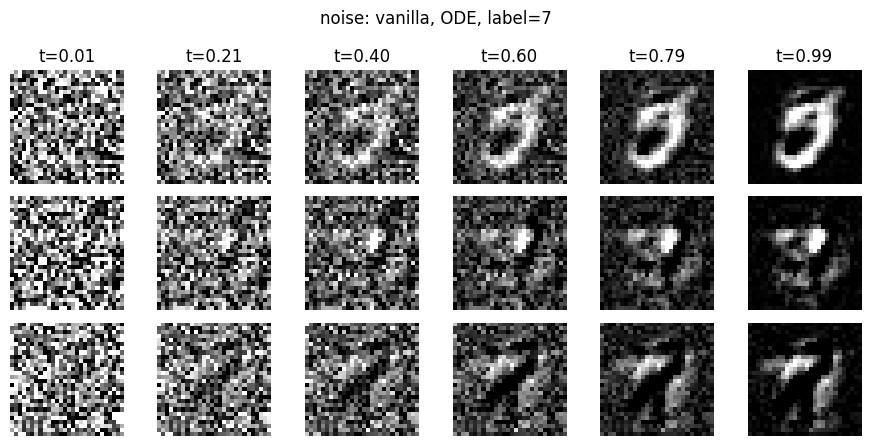

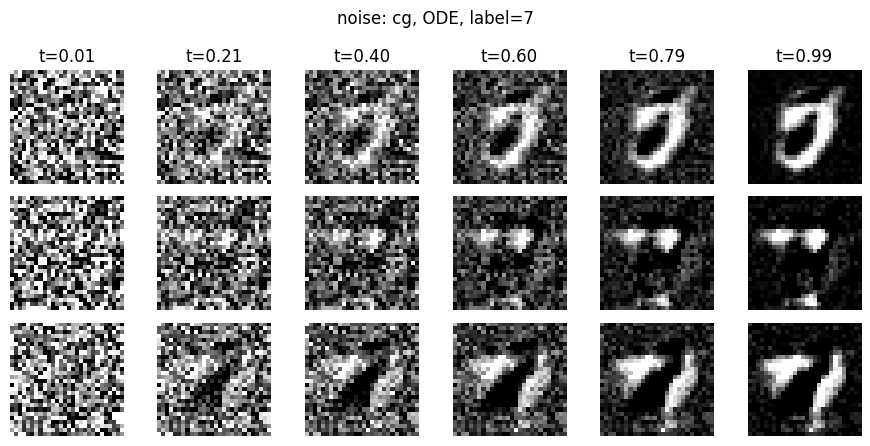

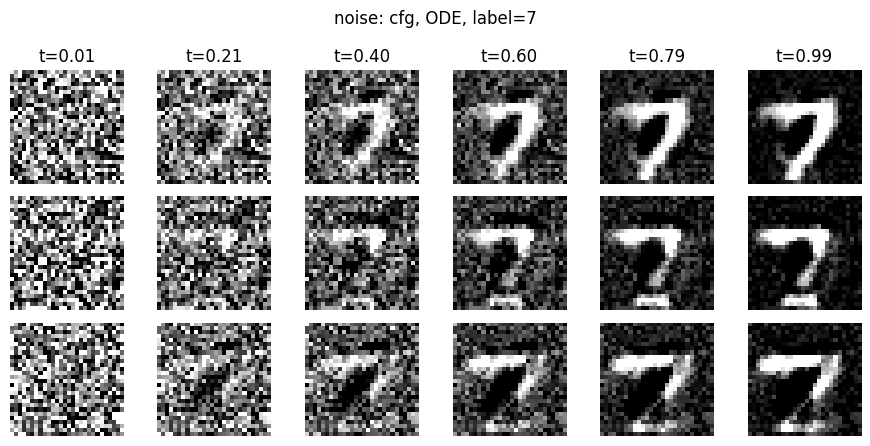

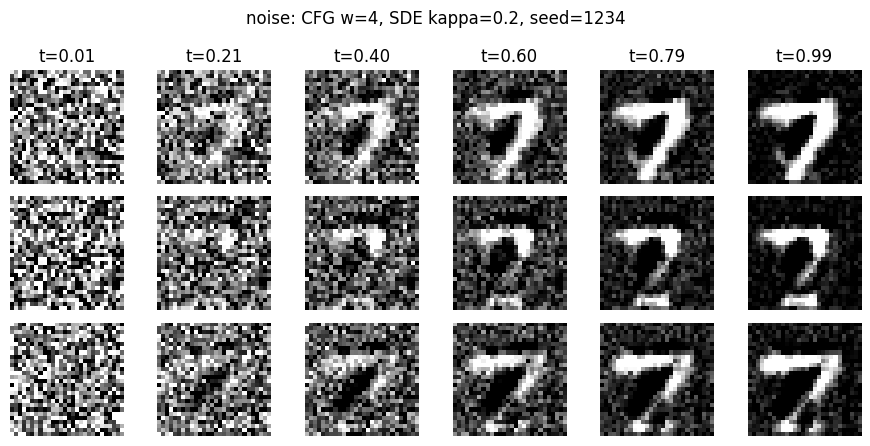

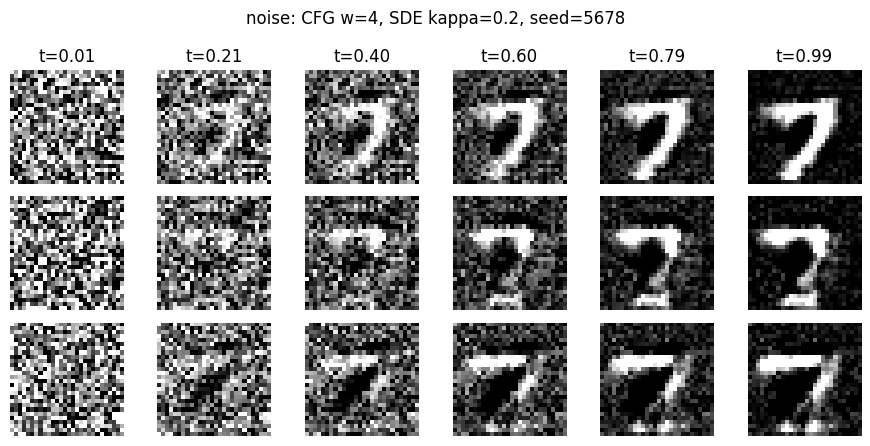

In [ ]:
def show_trace(frames,times,title):
    # frames: [saved times, batch, 784]; 각 행은 같은 sample의 변화다.
    fig,axes=plt.subplots(frames.shape[1],len(times),figsize=(len(times)*1.5,frames.shape[1]*1.5),squeeze=False)
    for row in range(frames.shape[1]):
        for col,tv in enumerate(times):
            axes[row,col].imshow(frames[col,row].reshape(28,28).clamp(-1,1),cmap='gray',vmin=-1,vmax=1)
            axes[row,col].axis('off')
            if row==0: axes[row,col].set_title(f't={tv:.2f}')
    fig.suptitle(title); plt.tight_layout(); plt.show()

TRACE_KIND='noise'  # 'flow'도 같은 방법으로 실험할 수 있다.
trace_x=sweep_x[:3]; trace_y=sweep_y[:3]
for method in ['baseline','vanilla','cg','cfg']:
    _,times,frames=sample(trace_x,trace_y,kind=TRACE_KIND,method=method,w=4.,trace=True)
    show_trace(frames,times,f'{TRACE_KIND}: {method}, ODE, label={TARGET_LABEL}')
for seed in [1234,5678]:
    _,times,frames=sample(trace_x,trace_y,kind=TRACE_KIND,method='cfg',w=4.,
                          steps=400,kappa=.2,seed=seed,trace=True)
    show_trace(frames,times,f'{TRACE_KIND}: CFG w=4, SDE kappa=0.2, seed={seed}')

## 10. 설정을 고정한 뒤 최종 test

Test는 real 데이터의 held-out 평가다. 생성 모델의 target MSE와 classifier의 classification 성능을 기록하며, 이를 생성 이미지의 전체 품질 점수로 해석하지 않는다. Test를 보며 반복적으로 w나 모델 설정을 고르지 않는다.

In [ ]:
print('Conditional/null test MSE:',evaluate_conditional(models,test_loader,seed=9876))
print('Classifier noisy test:',evaluate_classifier(classifier,test_loader,seed=9876))
print('Classifier clean test:',evaluate_classifier(classifier,test_loader,seed=9876,fixed_t=1.))
print('Baseline epoch:',baseline_epoch,'Conditional epoch:',conditional_epoch,
      'Classifier epoch:',clf_history[-1]['epoch'])
print('Checkpoint paths:',COND_CKPT,CLASSIFIER_CKPT)

Conditional/null test MSE: {'flow_conditional': 0.3060332332611084, 'flow_null': 0.33251381254196166, 'noise_conditional': 0.15214200909137726, 'noise_null': 0.1541130210876465}
Classifier noisy test: {'ce': 0.5798551448345184, 'accuracy': 0.7945}
Classifier clean test: {'ce': 0.05575709157348611, 'accuracy': 0.9821}
Baseline epoch: 300 Conditional epoch: 300 Classifier epoch: 50
Checkpoint paths: /content/drive/MyDrive/MNIST_Guidance/run_v1/conditional/last.pt /content/drive/MyDrive/MNIST_Guidance/run_v1/classifier/last.pt


## 11. 관찰한 결과와 한계

- **Guidance의 효과:** 시각적으로 Flow는 CG와 CFG 모두 원하는 숫자를 비교적 잘 생성했고, CFG가 더 깨끗하게 느껴졌다. Noise도 w를 높이면 숫자의 특징이 더 뚜렷해졌지만, 여전히 불분명한 sample이 있었다.
- **큰 w가 항상 더 좋은 것은 아니다:** Flow CFG는 w=2부터 평가 sample 1,000장의 label accuracy가 모두 100%였다. 더 큰 w에서는 accuracy의 추가 개선 없이 feature 분산은 줄고 pixel 범위를 벗어나는 정도는 커졌다. Noise CFG는 w=4 → 8에서 accuracy가 85.7% → 92.8%로 개선됐다.
- **결과 해석과 한계**: 이번 설정에서는 Flow CFG가 CG보다 시각적으로 더 깨끗했고, 같은 w에서 label accuracy도 높거나 같았다. 다만 Noise에서는 큰 w에서 CG의 accuracy가 더 높았으며, label accuracy만으로 이미지의 선명함이나 다양성을 판단할 수는 없다. 이번 평가는 Flow와 Noise prediction 모델을 모두 ODE로 sampling한 결과이므로, 두 모델의 차이를 ODE/SDE의 차이로 해석하지 않는다.
- **다음 실험:** 같은 데이터와 유사한 MLP에서도 학습 target과 guidance에 따라 결과가 크게 달라지는 점이 흥미로웠다. 정확한 원인은 아직 확인하지 못했으므로, 이번 결과를 baseline으로 U-Net·DiT를 적용해 label accuracy뿐 아니라 숫자의 가독성, 획과 배경, 다양성이 얼마나 개선되는지 비교하려 한다.

**참고:** Peter Holderrieth and Ezra Erives, *An Introduction to Flow Matching and Diffusion Models*, Ch.5, pp.34–40. [강의 홈페이지](https://diffusion.csail.mit.edu/). 이 notebook은 교재의 일반식과 Gaussian path 유도를 MNIST에 적용한 학습 실습이다.